# Definitions

In [7]:
dataset_specs = {
    'Birds': {
        'type': 'real',
        'n_targets': 19,
        'n_instances': 645
    },
    'Plant': {
        'type': 'real',
        'n_targets': 12,
        'n_instances': 978
    },
    'Gnegative': {
        'type': 'real',
        'n_targets': 8,
        'n_instances': 1392
    },
    'Enron': {
        'type': 'real',
        'n_targets': 53,
        'n_instances': 1702
    },
    'yeast': {
        'type': 'real',
        'n_targets': 14,
        'n_instances': 2417
    },
    'Human': {
        'type': 'real',
        'n_targets': 14,
        'n_instances': 3106
    },
    'Slashdot': {
        'type': 'real',
        'n_targets': 22,
        'n_instances': 3782
    },
    'Eukaryote': {
        'type': 'real',
        'n_targets': 22,
        'n_instances': 7766
    },
    'OHSUMED-F': {
        'type': 'real',
        'n_targets': 23,
        'n_instances': 13929
    },
    'Synthetic_Sudden1': {
        'type': 'synthetic',
        'synth_type': 'sudden1',
        'n_targets': 50,
        'n_instances': 20000
    },
    'Synthetic_Sudden2': {
        'type': 'synthetic',
        'synth_type': 'sudden2',
        'n_targets': 50,
        'n_instances': 20000
    },
    'Synthetic_Sudden3': {
        'type': 'synthetic',
        'synth_type': 'sudden3',
        'n_targets': 50,
        'n_instances': 20000
    },
    'Synthetic_Incremental1': {
        'type': 'synthetic',
        'synth_type': 'gradual1',
        'n_targets': 50,
        'n_instances': 20000
    },
    'Synthetic_Incremental2': {
        'type': 'synthetic',
        'synth_type': 'gradual2',
        'n_targets': 50,
        'n_instances': 20000
    },
    'Synthetic_Incremental3': {
        'type': 'synthetic',
        'synth_type': 'gradual3',
        'n_targets': 50,
        'n_instances': 20000
    },
    'Synthetic_Reoccurring': {
        'type': 'synthetic',
        'synth_type': 'reoccurring',
        'n_targets': 50,
        'n_instances': 20000
    },
    'tmc2007-500': {
        'type': 'real',
        'n_targets': 22,
        'n_instances': 28600
    },
    'Mediamill': {
        'type': 'real',
        'n_targets': 101,
        'n_instances': 43907
    },
    'Imdb': {
        'type': 'real',
        'n_targets': 28,
        'n_instances': 120900
    }
}

In [9]:
# read data from outputs/predictions/_dataset-name_/_method-name_.pkl

datasets_to_test = [
    'Synthetic_Sudden2',
    'Synthetic_Sudden1',
    'Synthetic_Sudden3',
    'Synthetic_Incremental1',
    'Synthetic_Incremental2',
    'Synthetic_Incremental3',
    'Synthetic_Reoccurring',
    'Birds',
    'Enron',
    'Eukaryote',
    'Gnegative',
    'Human',
    'Imdb',
    'Mediamill',
    'OHSUMED-F',
    'Plant',
    'Slashdot',
    'tmc2007-500',
    'yeast',
]

### File structure:

"""
'dataset': DATASET,
'dataset_type': DATA_TYPE,
'detector_params': detector_info[det_name],
'drift_points': drift_points,
'metrics': {
    'accuracy': util.accuracy_example(np.array(results_true), np.array(preds)),
    'hamming_score': 1 - util.hamming_loss(np.array(results_true), np.array(preds)),
    'f1_example': util.f1_example(np.array(results_true), np.array(preds)),
    'f1_micro': util.f1_micro(np.array(results_true), np.array(preds)),
    'f1_macro': util.f1_macro(np.array(results_true), np.array(preds)),
},
'time': {
    'seconds': elapsed_seconds,
    'started_at': started_at.isoformat(),
    'ended_at': ended_at.isoformat(),
    'processed_samples': idx,
    'stream_samples_seen': stream_idx,
},
'memory': {
    'python_current_mb': _bytes_to_mb(python_current_bytes),
    'python_peak_mb': _bytes_to_mb(python_peak_bytes),
    'rss_before_mb': rss_before_mb,
    'rss_after_mb': rss_after_mb,
    'rss_peak_sampled_mb': rss_peak_mb,
    'rss_peak_delta_mb': (
        None
        if rss_before_mb is None or rss_peak_mb is None
        else rss_peak_mb - rss_before_mb
    ),
},
'predictions': np.array(preds),
"""

# Effectiveness Tables

In [49]:
import os
import pickle

accuracies = {}
hamming_scores = {}
f1_example_scores = {}
f1_micro_scores = {}
f1_macro_scores = {}
times = {}
times_per_sample = {}
memory_usages = {}

for dataset in datasets_to_test:
    if 'Synthetic' in dataset:
        continue
    methods = os.listdir(f'outputs/predictions/{dataset}')
    methods = [method for method in methods if 'LACE-' not in method]
    for method in methods:
        with open(f'outputs/predictions/{dataset}/{method}', 'rb') as f:
            data = pickle.load(f)
        
        method = method.replace('.pkl', '')
        
        accuracies[(dataset, method)] = data['metrics']['accuracy']
        hamming_scores[(dataset, method)] = data['metrics']['hamming_score']
        f1_example_scores[(dataset, method)] = data['metrics']['f1_example']
        f1_micro_scores[(dataset, method)] = data['metrics']['f1_micro']
        f1_macro_scores[(dataset, method)] = data['metrics']['f1_macro']
        times[(dataset, method)] = data['time']['seconds']
        times_per_sample[(dataset, method)] = data['time']['seconds'] / data['time']['processed_samples']
        memory_usages[(dataset, method)] = data['memory']['rss_peak_sampled_mb']

In [50]:
import csv

base_path = '/Users/mehmetkadrigofralilar/Desktop/LACE/outputs/tables_figures/effectiveness'

### Accuracy

In [54]:
with open(f'{base_path}/accuracies.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    # make the rows datasets, and columns methods
    methods = set(method for _, method in accuracies.keys())
    writer.writerow(['Dataset'] + list(methods))
    for dataset in datasets_to_test:
        if 'Synthetic' in dataset:
            continue
        row = [dataset]
        for method in methods:
            accuracy = accuracies.get((dataset, method), 'N/A')
            row.append(f'{accuracy:.4f}')
        writer.writerow(row)

### Hamming Score

In [14]:
with open(f'{base_path}/hamming_scores.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    # make the rows datasets, and columns methods
    methods = set(method for _, method in hamming_scores.keys())
    writer.writerow(['Dataset'] + list(methods))
    for dataset in datasets_to_test:
        row = [dataset]
        for method in methods:
            score = hamming_scores.get((dataset, method), 'N/A')
            row.append(f'{score:.4f}')
        writer.writerow(row)

### F1 Example

In [15]:
with open(f'{base_path}/f1_example_scores.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    # make the rows datasets, and columns methods
    methods = set(method for _, method in f1_example_scores.keys())
    writer.writerow(['Dataset'] + list(methods))
    for dataset in datasets_to_test:
        row = [dataset]
        for method in methods:
            score = f1_example_scores.get((dataset, method), 'N/A')
            row.append(f'{score:.4f}')
        writer.writerow(row)

### F1 Micro

In [55]:
with open(f'{base_path}/f1_micro_scores.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    # make the rows datasets, and columns methods
    methods = set(method for _, method in f1_micro_scores.keys())
    writer.writerow(['Dataset'] + list(methods))
    for dataset in datasets_to_test:
        if 'Synthetic' in dataset:
            continue
        row = [dataset]
        for method in methods:
            score = f1_micro_scores.get((dataset, method), 'N/A')
            row.append(f'{score:.4f}')
        writer.writerow(row)

### F1 Macro

In [56]:
with open(f'{base_path}/f1_macro_scores.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    # make the rows datasets, and columns methods
    methods = set(method for _, method in f1_macro_scores.keys())
    writer.writerow(['Dataset'] + list(methods))
    for dataset in datasets_to_test:
        if 'Synthetic' in dataset:
            continue
        row = [dataset]
        for method in methods:
            score = f1_macro_scores.get((dataset, method), 'N/A')
            row.append(f'{score:.4f}')
        writer.writerow(row)

### Time/Time per Sample

In [18]:
with open(f'{base_path}/times.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)

    methods = sorted(set(method for _, method in times.keys()))
    header_1 = ['Dataset']
    for method in methods:
        header_1.extend([method, method])
    header_2 = ['']
    for method in methods:
        header_2.extend(['Time', 'Time per sample'])

    writer.writerow(header_1)
    writer.writerow(header_2)

    for dataset in sorted(datasets_to_test):
        row = [dataset]

        for method in methods:
            time = times.get((dataset, method), None)
            time_per_sample = times_per_sample.get((dataset, method), None)

            row.append(f'{time:.2f}' if time is not None else 'N/A')
            row.append(f'{time_per_sample:.6f}' if time_per_sample is not None else 'N/A')

        writer.writerow(row)

### Memory

In [19]:
with open(f'{base_path}/memory_usages.csv', 'w', newline='') as csvfile:
    writer = csv.writer(csvfile)
    methods = set(method for _, method in memory_usages.keys())
    writer.writerow(['Dataset'] + list(methods))
    for dataset in datasets_to_test:
        row = [dataset]
        for method in methods:
            memory_usage = memory_usages.get((dataset, method), 'N/A')
            row.append(f'{memory_usage:.2f}' if memory_usage != 'N/A' else 'N/A')
        writer.writerow(row)

## Bar Chart

In [1]:
import pandas as pd

base_path = '/Users/mehmetkadrigofralilar/Desktop/LACE_og/outputs/tables_figures/effectiveness'

df_acc = pd.read_csv(f'{base_path}/accuracies.csv')
#df_hamming = pd.read_csv(f'{base_path}/hamming_scores.csv')
#df_f1_example = pd.read_csv(f'{base_path}/f1_example_scores.csv')
df_f1_micro = pd.read_csv(f'{base_path}/f1_micro_scores.csv')
df_f1_macro = pd.read_csv(f'{base_path}/f1_macro_scores.csv')

dfs = {
    'Example-based Accuracy': df_acc,
    #'Hamming Score': df_hamming,
    #'Example F1': df_f1_example,
    'Micro-averaged F1': df_f1_micro,
    'Macro-averaged F1': df_f1_macro,
}

# Clean and index all dataframes
for name in dfs:
    df = dfs[name].copy()
    df = df.set_index('Dataset')
    df = df.apply(pd.to_numeric, errors='coerce')
    dfs[name] = df

for name in dfs:
    df = dfs[name]
    dfs[name] = df

rank_dfs = {
    name: df.rank(axis=1, ascending=False, method='average')
    for name, df in dfs.items()
}

rank_summary = pd.DataFrame({
    name: rank_df.mean(axis=0)
    for name, rank_df in rank_dfs.items()
})

rank_summary['Cumulative Rank'] = rank_summary.sum(axis=1)
rank_summary = rank_summary.sort_values('Cumulative Rank', ascending=True)

print(rank_summary)


            Example-based Accuracy  Micro-averaged F1  Macro-averaged F1  \
LACE                      4.166667           4.916667           7.750000   
LD3                       4.000000           4.166667          10.666667   
RDDM                      4.708333           6.791667          10.083333   
ND                        8.083333           7.000000           6.916667   
ADWIN                     6.583333           6.500000          10.083333   
MDDM_G                    9.166667           9.500000           7.583333   
MDDM_E                    9.083333           9.750000           7.500000   
MDDM_A                    8.916667           9.958333           7.500000   
FHDDMS_add                9.666667           9.875000           7.666667   
KSWIN                    11.208333           9.208333           7.458333   
FHDDM                     9.916667          10.083333           8.125000   
SeqDrift2                10.291667           9.875000           8.375000   
HDDM_W      

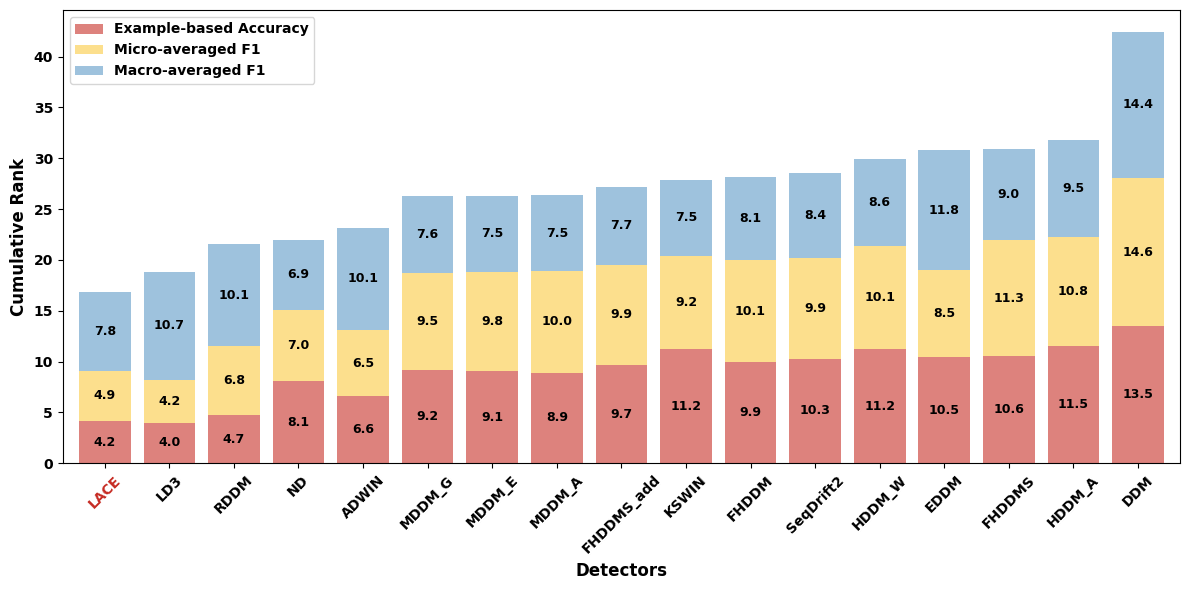

In [3]:
import matplotlib.pyplot as plt

plot_df = rank_summary.drop(columns=['Cumulative Rank'])
plot_df = plot_df.loc[rank_summary.sort_values('Cumulative Rank').index]

#colors = ["#c62b23",'#fc8d59',"#fbc226",'#abd9e9','#2c7bb6']
colors = ["#c62b2396","#fbc22686","#2c7ab675"]

ax = plot_df.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6),
    width=0.8,
    color=colors,
)

ax.set_xlabel('Detectors', fontsize=12, fontweight='bold')
ax.set_ylabel('Cumulative Rank', fontsize=12, fontweight='bold')

# Add values to each colored section
for container in ax.containers:
    ax.bar_label(
        container,
        label_type='center',   # puts label inside each colored section
        fontsize=9,
        fontweight='bold',
        fmt='%.1f'             # use '%d' if values are integers
    )

ax.legend(
    loc='upper left',
    frameon=True,
    fontsize=11,
    prop={'weight': 'bold'}
)

plt.xticks(rotation=45, ha='center', fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')

for tick in ax.get_xticklabels():
    if tick.get_text() == 'LACE':
        tick.set_color('#c62b23')

plt.tight_layout()

plt.savefig(
    f'{base_path}/cumulative_rank_bar_chart_acc_mic_mac.pdf',
    dpi=600,
    bbox_inches='tight'
)

plt.show()

# Drift Delay

In [32]:
os.getcwd()

'/Users/mehmetkadrigofralilar/Desktop/LACE_og/outputs/tables_figures'

In [34]:
os.chdir("..")

In [108]:
import os

# Read drift points from pickle files and write to the drift_points.txt file
path = "outputs/predictions/"
drift_points_by_name = {}
try:
    for dataset_name in os.listdir(path):
        dataset_path = os.path.join(path, dataset_name)
        if os.path.isdir(dataset_path):
            for filename in os.listdir(dataset_path):
                if filename.endswith(".pkl"):
                    method_name = filename.split(".pkl")[0]
                    if method_name.startswith("LACE-"):
                        continue
                    file_path = os.path.join(dataset_path, filename)
                    with open(file_path, "rb") as f:
                        drift_points = pickle.load(f)['drift_points']
                        if dataset_name not in drift_points_by_name:
                            drift_points_by_name[dataset_name] = {}
                        drift_points_by_name[dataset_name][method_name] = drift_points
except Exception as e:
    print(f"An error occurred while reading drift points: {e}")

### drift_points.csv

In [35]:
import csv

output_path = "/Users/mehmetkadrigofralilar/Desktop/LACE_og/outputs/tables_figures/drift_points/drift_points_by_name.csv"

# Collect all method names so CSV columns are consistent
all_methods = sorted({
    method_name
    for methods in drift_points_by_name.values()
    for method_name in methods.keys()
})

with open(output_path, "w", newline="") as f:
    writer = csv.writer(f)

    # Header row
    writer.writerow(["dataset"] + all_methods)

    # Data rows
    for dataset_name, methods in sorted(drift_points_by_name.items()):
        row = [dataset_name]

        for method_name in all_methods:
            drift_points = methods.get(method_name, [])

            drift_points_list = [
                str(drift_point["stream_idx"])
                for drift_point in drift_points
            ]

            cell_value = ";".join(drift_points_list)
            row.append(cell_value)

        writer.writerow(row)

NameError: name 'drift_points_by_name' is not defined

### drift_delay, false_positive, true_positive

In [114]:
import numpy as np


true_positives_by_name = {}
false_positives_by_name = {}
average_delay_by_name = {}

# first fill the above dictionaries using the drift_points_by_name and the true drift points for each dataset (which can be obtained from the dataset_specs)
# the rule is: the real drift points are at 4000 and 10000. The closest detected drift AFTER or at the real drift point is considered a true positive, and the rest is considered false positives. The delay is calculated as the difference between the true positives and the real drift point.

try:
    for dataset in drift_points_by_name:
        if 'Synthetic' not in dataset:  # Only calculate for real datasets
            continue
        true_positives_by_name[dataset] = {}
        false_positives_by_name[dataset] = {}
        average_delay_by_name[dataset] = {}

        for method in drift_points_by_name[dataset]:
            detected_points = drift_points_by_name[dataset][method]
            print(f"Dataset: {dataset}, Method: {method}, Detected Points: {detected_points}")
            drift_points_list = [
                int(drift_point["stream_idx"])
                for drift_point in detected_points
            ]
            print(f"Drift points list for {dataset} - {method}: {drift_points_list}")
            true_drift_points = [4000, 10000]

            true_positives = 0
            false_positives = 0
            delays = []

            for true_point in true_drift_points:
                # Find the closest detected point that is >= true_point
                candidates = [p for p in drift_points_list if p >= true_point]
                if candidates:
                    closest_point = min(candidates, key=lambda x: x - true_point)
                    true_positives += 1
                    delays.append(closest_point - true_point)

            false_positives = len(drift_points_list) - true_positives
            average_delay = np.mean(delays) if delays else None

            true_positives_by_name[dataset][method] = true_positives
            false_positives_by_name[dataset][method] = false_positives
            average_delay_by_name[dataset][method] = average_delay
except Exception as e:
    print(f"An error occurred while calculating drift point metrics: {e}")


# save the above metrics to 3 csv files: true_positives_by_name.csv, false_positives_by_name.csv, average_delay_by_name.csv with rows as dataset and columns as method names and values as the corresponding metric value
# if the file does not exist, create it and write the header. If it exists, overwrite it.
try:
    with open("/Users/mehmetkadrigofralilar/Desktop/LACE/outputs/tables_figures/drift_points/true_positives_by_name.csv", "w") as f:
        method_names = set()
        for dataset in true_positives_by_name:
            method_names.update(true_positives_by_name[dataset].keys())
        method_names = sorted(method_names)

        if 'LD3' in method_names:
            method_names.remove('LD3')
            method_names.insert(0, 'LD3')
        if 'Ours' in method_names:
            method_names.remove('Ours')
            method_names.insert(0, 'Ours')

        f.write("Dataset," + ",".join(method_names) + "\n")
        for dataset in sorted(true_positives_by_name.keys()):
            row = [dataset]
            for method in method_names:
                row.append(str(true_positives_by_name[dataset].get(method, 0)))
            f.write(",".join(row) + "\n")

    with open("/Users/mehmetkadrigofralilar/Desktop/LACE/outputs/tables_figures/drift_points/false_positives_by_name.csv", "w") as f:
        method_names = set()
        for dataset in false_positives_by_name:
            method_names.update(false_positives_by_name[dataset].keys())
        method_names = sorted(method_names)

        if 'LD3' in method_names:
            method_names.remove('LD3')
            method_names.insert(0, 'LD3')
        if 'Ours' in method_names:
            method_names.remove('Ours')
            method_names.insert(0, 'Ours')
            
        f.write("Dataset," + ",".join(method_names) + "\n")
        for dataset in sorted(false_positives_by_name.keys()):
            row = [dataset]
            for method in method_names:
                row.append(str(false_positives_by_name[dataset].get(method, 0)))
            f.write(",".join(row) + "\n")

    with open("/Users/mehmetkadrigofralilar/Desktop/LACE/outputs/tables_figures/drift_points/average_delay_by_name.csv", "w") as f:
        method_names = set()
        for dataset in average_delay_by_name:
            method_names.update(average_delay_by_name[dataset].keys())
        method_names = sorted(method_names)

        if 'LD3' in method_names:
            method_names.remove('LD3')
            method_names.insert(0, 'LD3')
        if 'Ours' in method_names:
            method_names.remove('Ours')
            method_names.insert(0, 'Ours')
            
        f.write("Dataset," + ",".join(method_names) + "\n")
        for dataset in sorted(average_delay_by_name.keys()):
            row = [dataset]
            for method in method_names:
                delay_value = average_delay_by_name[dataset].get(method, None)
                row.append(str(delay_value) if delay_value is not None else "")
            f.write(",".join(row) + "\n")
except Exception as e:
    print(f"An error occurred while writing drift point metrics to CSV: {e}")

Dataset: Synthetic_Reoccurring, Method: MDDM_E, Detected Points: []
Drift points list for Synthetic_Reoccurring - MDDM_E: []
Dataset: Synthetic_Reoccurring, Method: EDDM, Detected Points: [{'stream_idx': 2022, 'processed_idx': 1726}]
Drift points list for Synthetic_Reoccurring - EDDM: [2022]
Dataset: Synthetic_Reoccurring, Method: MDDM_G, Detected Points: []
Drift points list for Synthetic_Reoccurring - MDDM_G: []
Dataset: Synthetic_Reoccurring, Method: LACE, Detected Points: [{'stream_idx': 4549, 'processed_idx': 4000}, {'stream_idx': 6075, 'processed_idx': 5500}, {'stream_idx': 7608, 'processed_idx': 7000}, {'stream_idx': 8118, 'processed_idx': 7500}, {'stream_idx': 9132, 'processed_idx': 8500}, {'stream_idx': 9643, 'processed_idx': 9000}, {'stream_idx': 10757, 'processed_idx': 10000}, {'stream_idx': 11925, 'processed_idx': 11000}, {'stream_idx': 12508, 'processed_idx': 11500}, {'stream_idx': 13649, 'processed_idx': 12500}, {'stream_idx': 14219, 'processed_idx': 13000}, {'stream_idx'

In [36]:
# read from average_delay_by_name.csv and true_positives_by_name.csv

base_path = "/Users/mehmetkadrigofralilar/Desktop/LACE_og/outputs/tables_figures/drift_points"


df_average_delay = pd.read_csv(f'{base_path}/average_delay_by_name.csv')
df_average_delay = df_average_delay.set_index('Dataset')
df_average_delay = df_average_delay.drop(
    columns=[col for col in df_average_delay.columns if df_average_delay[col].isnull().all()]
)

df_true_positives = pd.read_csv(f'{base_path}/true_positives_by_name.csv')
df_true_positives = df_true_positives.set_index('Dataset')
#drop if all values in a column are 0
df_true_positives = df_true_positives.drop(
    columns=[col for col in df_true_positives.columns if (df_true_positives[col] == 0).all()]
)

print(df_average_delay)
print(df_true_positives)

                           LD3   ADWIN     DDM   LACE   RDDM
Dataset                                                     
Synthetic_Incremental1  1118.0     NaN  1776.5  707.0  139.0
Synthetic_Incremental2  1393.5     NaN  1411.5  119.0   29.0
Synthetic_Incremental3  1146.0  1181.0     NaN  118.5    NaN
Synthetic_Reoccurring   3621.5  3875.0  2055.0  653.0  366.0
Synthetic_Sudden1       1107.0     NaN  1169.0  669.0  114.0
Synthetic_Sudden2        673.5     NaN  1172.0  669.0  139.0
Synthetic_Sudden3        817.5     NaN  1170.5  668.5  114.0
                        LD3  ADWIN  DDM  LACE  RDDM
Dataset                                            
Synthetic_Incremental1    2      0    2     2     1
Synthetic_Incremental2    2      0    2     2     1
Synthetic_Incremental3    2      1    0     2     0
Synthetic_Reoccurring     2      1    2     2     1
Synthetic_Sudden1         2      0    2     2     1
Synthetic_Sudden2         2      0    2     2     1
Synthetic_Sudden3         2      0 

In [39]:
# get the average delays per method across datasets

average_delays_per_method = df_average_delay.mean(axis=0)

# get ld3
ld3_average_delay = average_delays_per_method.get('LD3', None)
lace_average_delay = average_delays_per_method.get('LACE', None)

# calculate the percentage improvement of LACE over LD3 in average delay
if ld3_average_delay is not None and lace_average_delay is not None:
    improvement = (ld3_average_delay - lace_average_delay) / ld3_average_delay * 100
    print(f"Average Delay - LD3: {ld3_average_delay:.2f}, LACE: {lace_average_delay:.2f}, Improvement: {improvement:.2f}%")

# calculate the max improvement in average delay of LACE over LD3 across datasets
max_improvement = 0
for dataset in df_average_delay.index:
    ld3_delay = df_average_delay.loc[dataset, 'LD3'] if 'LD3' in df_average_delay.columns else None
    lace_delay = df_average_delay.loc[dataset, 'LACE'] if 'LACE' in df_average_delay.columns else None
    if ld3_delay is not None and lace_delay is not None and ld3_delay > 0:
        dataset_improvement = (ld3_delay - lace_delay) / ld3_delay * 100
        max_improvement = max(max_improvement, dataset_improvement)
        print(f"Dataset: {dataset}, LD3 Delay: {ld3_delay:.2f}, LACE Delay: {lace_delay:.2f}, Improvement: {dataset_improvement:.2f}%")

Average Delay - LD3: 1411.00, LACE: 514.86, Improvement: 63.51%
Dataset: Synthetic_Incremental1, LD3 Delay: 1118.00, LACE Delay: 707.00, Improvement: 36.76%
Dataset: Synthetic_Incremental2, LD3 Delay: 1393.50, LACE Delay: 119.00, Improvement: 91.46%
Dataset: Synthetic_Incremental3, LD3 Delay: 1146.00, LACE Delay: 118.50, Improvement: 89.66%
Dataset: Synthetic_Reoccurring, LD3 Delay: 3621.50, LACE Delay: 653.00, Improvement: 81.97%
Dataset: Synthetic_Sudden1, LD3 Delay: 1107.00, LACE Delay: 669.00, Improvement: 39.57%
Dataset: Synthetic_Sudden2, LD3 Delay: 673.50, LACE Delay: 669.00, Improvement: 0.67%
Dataset: Synthetic_Sudden3, LD3 Delay: 817.50, LACE Delay: 668.50, Improvement: 18.23%


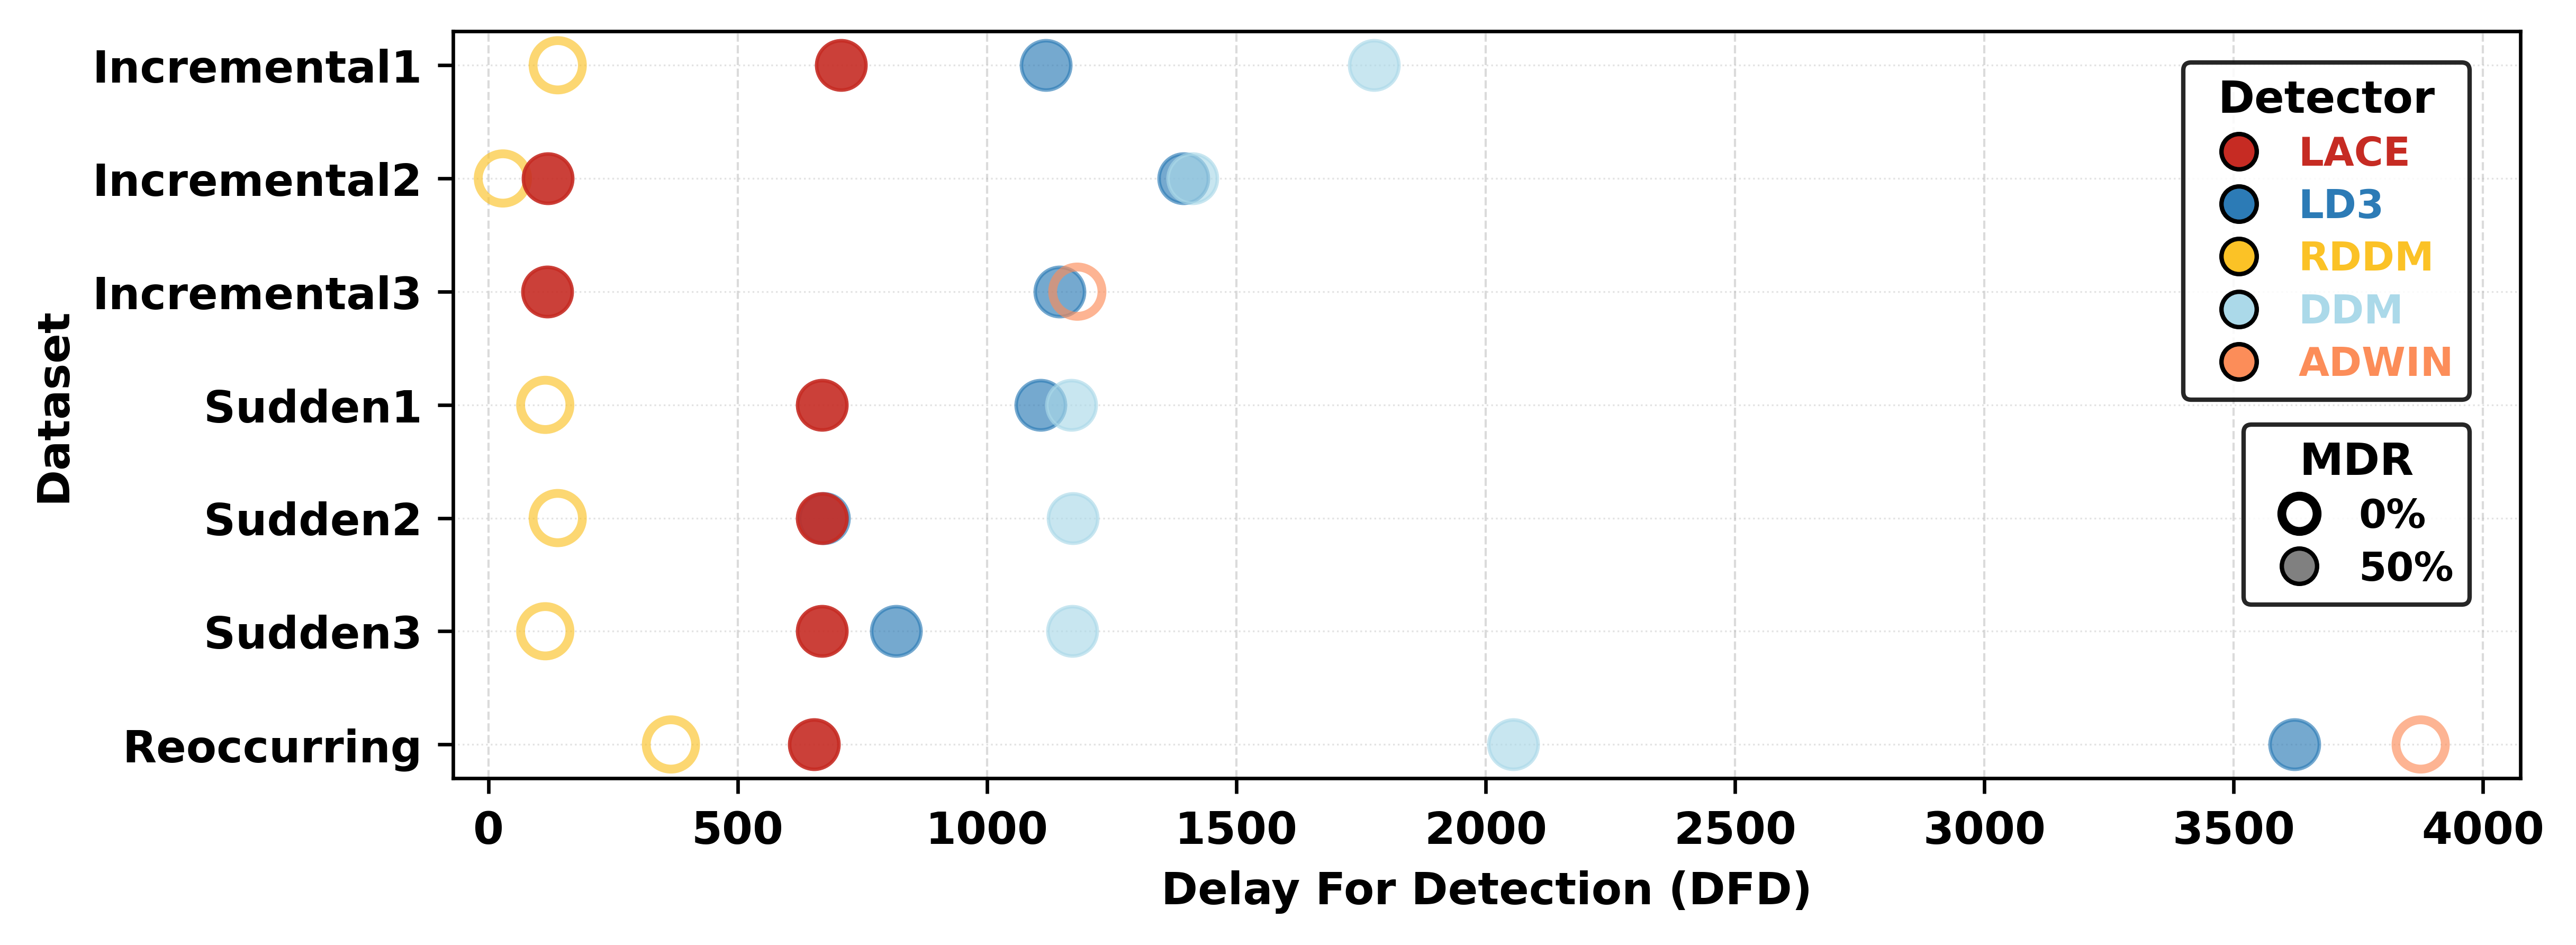

Saved figure to: synthetic_dfd_dataset_mdr_fill_scatter.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# SETTINGS
# ============================================================

TOTAL_REAL_DRIFTS = 2

detector_order = ["LACE", "LD3", "RDDM", "DDM", "ADWIN"]

dataset_order = [
    "Synthetic_Incremental1",
    "Synthetic_Incremental2",
    "Synthetic_Incremental3",
    "Synthetic_Sudden1",
    "Synthetic_Sudden2",
    "Synthetic_Sudden3",
    "Synthetic_Reoccurring",
]

dataset_display = {
    "Synthetic_Incremental1": "Incremental1",
    "Synthetic_Incremental2": "Incremental2",
    "Synthetic_Incremental3": "Incremental3",
    "Synthetic_Reoccurring": "Reoccurring",
    "Synthetic_Sudden1": "Sudden1",
    "Synthetic_Sudden2": "Sudden2",
    "Synthetic_Sudden3": "Sudden3",
}

detector_colors = {
    "LACE": "#c62b23",
    "LD3": "#2c7bb6",
    "RDDM": "#fbc226",
    "DDM": "#abd9e9",
    "ADWIN": "#fc8d59",
}

output_path = "synthetic_dfd_dataset_mdr_fill_scatter.png"


# ============================================================
# PREPARE DATA
# ============================================================

available_detectors = [
    d for d in detector_order
    if d in df_average_delay.columns and d in df_true_positives.columns
]

available_datasets = [
    d for d in dataset_order
    if d in df_average_delay.index and d in df_true_positives.index
]

records = []

for dataset in available_datasets:
    for detector in available_detectors:
        delay = df_average_delay.loc[dataset, detector]

        if pd.isna(delay):
            continue

        tp = df_true_positives.loc[dataset, detector]
        mdr = round((1 - tp / TOTAL_REAL_DRIFTS) * 100)

        records.append({
            "Dataset": dataset,
            "Detector": detector,
            "DFD": float(delay),
            "MDR": int(mdr),
        })

plot_df = pd.DataFrame(records)

dataset_to_y = {
    dataset: i
    for i, dataset in enumerate(available_datasets)
}

plot_df["Dataset_y"] = plot_df["Dataset"].map(dataset_to_y)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(8.4, 4.2))

# Draw LACE last so it is always visually on top.
plot_order = [d for d in available_detectors if d != "LACE"] + ["LACE"]

for detector in plot_order:
    detector_df = plot_df[plot_df["Detector"] == detector]
    color = detector_colors[detector]

    for _, row in detector_df.iterrows():
        if row["MDR"] == 0:
            marker = "o"
            facecolor = color
            edgecolor = color
            linewidth = 0.8
        elif row["MDR"] == 50:
            marker = "o"
            facecolor = "none"
            edgecolor = color
            linewidth = 2.0
        else:
            marker = "X"
            facecolor = color
            edgecolor = "black"
            linewidth = 0.8

        ax.scatter(
            row["DFD"],
            row["Dataset_y"],
            marker=marker,
            s=125,
            facecolors=facecolor,
            edgecolors=edgecolor,
            linewidth=linewidth,
            alpha=0.65 if detector != "LACE" else 0.90,
            zorder=10 if detector == "LACE" else 3,
        )


# ============================================================
# AXIS STYLE
# ============================================================

ax.set_xlabel("Delay For Detection (DFD)", fontweight="bold")
ax.set_ylabel("Dataset", fontweight="bold")

ax.set_yticks(list(dataset_to_y.values()))
ax.set_yticklabels([dataset_display[d] for d in available_datasets])

for tick in ax.get_xticklabels() + ax.get_yticklabels():
    tick.set_fontweight("bold")

ax.set_xlim(plot_df["DFD"].min() - 100, plot_df["DFD"].max() + 200)
ax.invert_yaxis()

ax.grid(True, axis="x", linestyle="--", linewidth=0.5, alpha=0.45)
ax.grid(True, axis="y", linestyle=":", linewidth=0.4, alpha=0.35)


# ============================================================
# LEGEND: DETECTOR | MDR INSIDE TOP-RIGHT, LINE BY LINE
# ============================================================

legend_mdr_by_detector = {
    "LACE": 0,
    "LD3": 0,
    "DDM": 0,
    "RDDM": 50,
    "ADWIN": 50,
}

legend_order = ["LACE", "LD3", "DDM", "RDDM", "ADWIN"]

combined_handles = []

for detector in legend_order:
    if detector not in plot_df["Detector"].unique():
        continue

    mdr = legend_mdr_by_detector[detector]
    color = detector_colors[detector]

    if mdr == 0:
        facecolor = color
        edgecolor = "black"
        linewidth = 0.8
    else:
        facecolor = "none"
        edgecolor = color
        linewidth = 2.0

    combined_handles.append(
        plt.Line2D(
            [0], [0],
            marker="o",
            linestyle="None",
            label=f"{detector} | {mdr}%",
            markerfacecolor=facecolor,
            markeredgecolor=edgecolor,
            markeredgewidth=linewidth,
            markersize=8,
        )
    )

legend = ax.legend(
    handles=combined_handles,
    title="Detector | MDR",
    loc="upper right",
    bbox_to_anchor=(0.985, 0.985),
    ncol=1,
    frameon=True,
    framealpha=0.85,
    facecolor="white",
    edgecolor="black",
    prop={"weight": "bold", "size": 9},
    title_fontproperties={"weight": "bold", "size": 10},
    borderpad=0.4,
    labelspacing=0.35,
    handletextpad=0.5,
)

for text in legend.get_texts():
    detector = text.get_text().split("|")[0].strip()
    text.set_color(detector_colors.get(detector, "black"))
    text.set_fontweight("bold")


# ============================================================
# SAVE
# ============================================================

plt.subplots_adjust(bottom=0.32)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved figure to: {output_path}")

# Plots

In [3]:
metrics_to_plot = [
    'accuracy',
]

metrics_to_not_plot = [
    'hamming',
    'f1_example',
    'f1_micro',
    'f1_macro'
]

In [4]:
import os

os.chdir("/Users/mehmetkadrigofralilar/Desktop/lace")

In [5]:
import util

Dataset: Birds
Loading predictions from outputs/predictions/Birds
Loading dataset Birds to get true labels...
Loaded 645 true labels before zero-label filtering
Loaded predictions for 5 detectors
Loaded 351 true labels after zero-label filtering
Plotting results for Birds...
  Plot(s) will be saved to /Users/mehmetkadrigofralilar/Desktop/LACE/outputs/plots


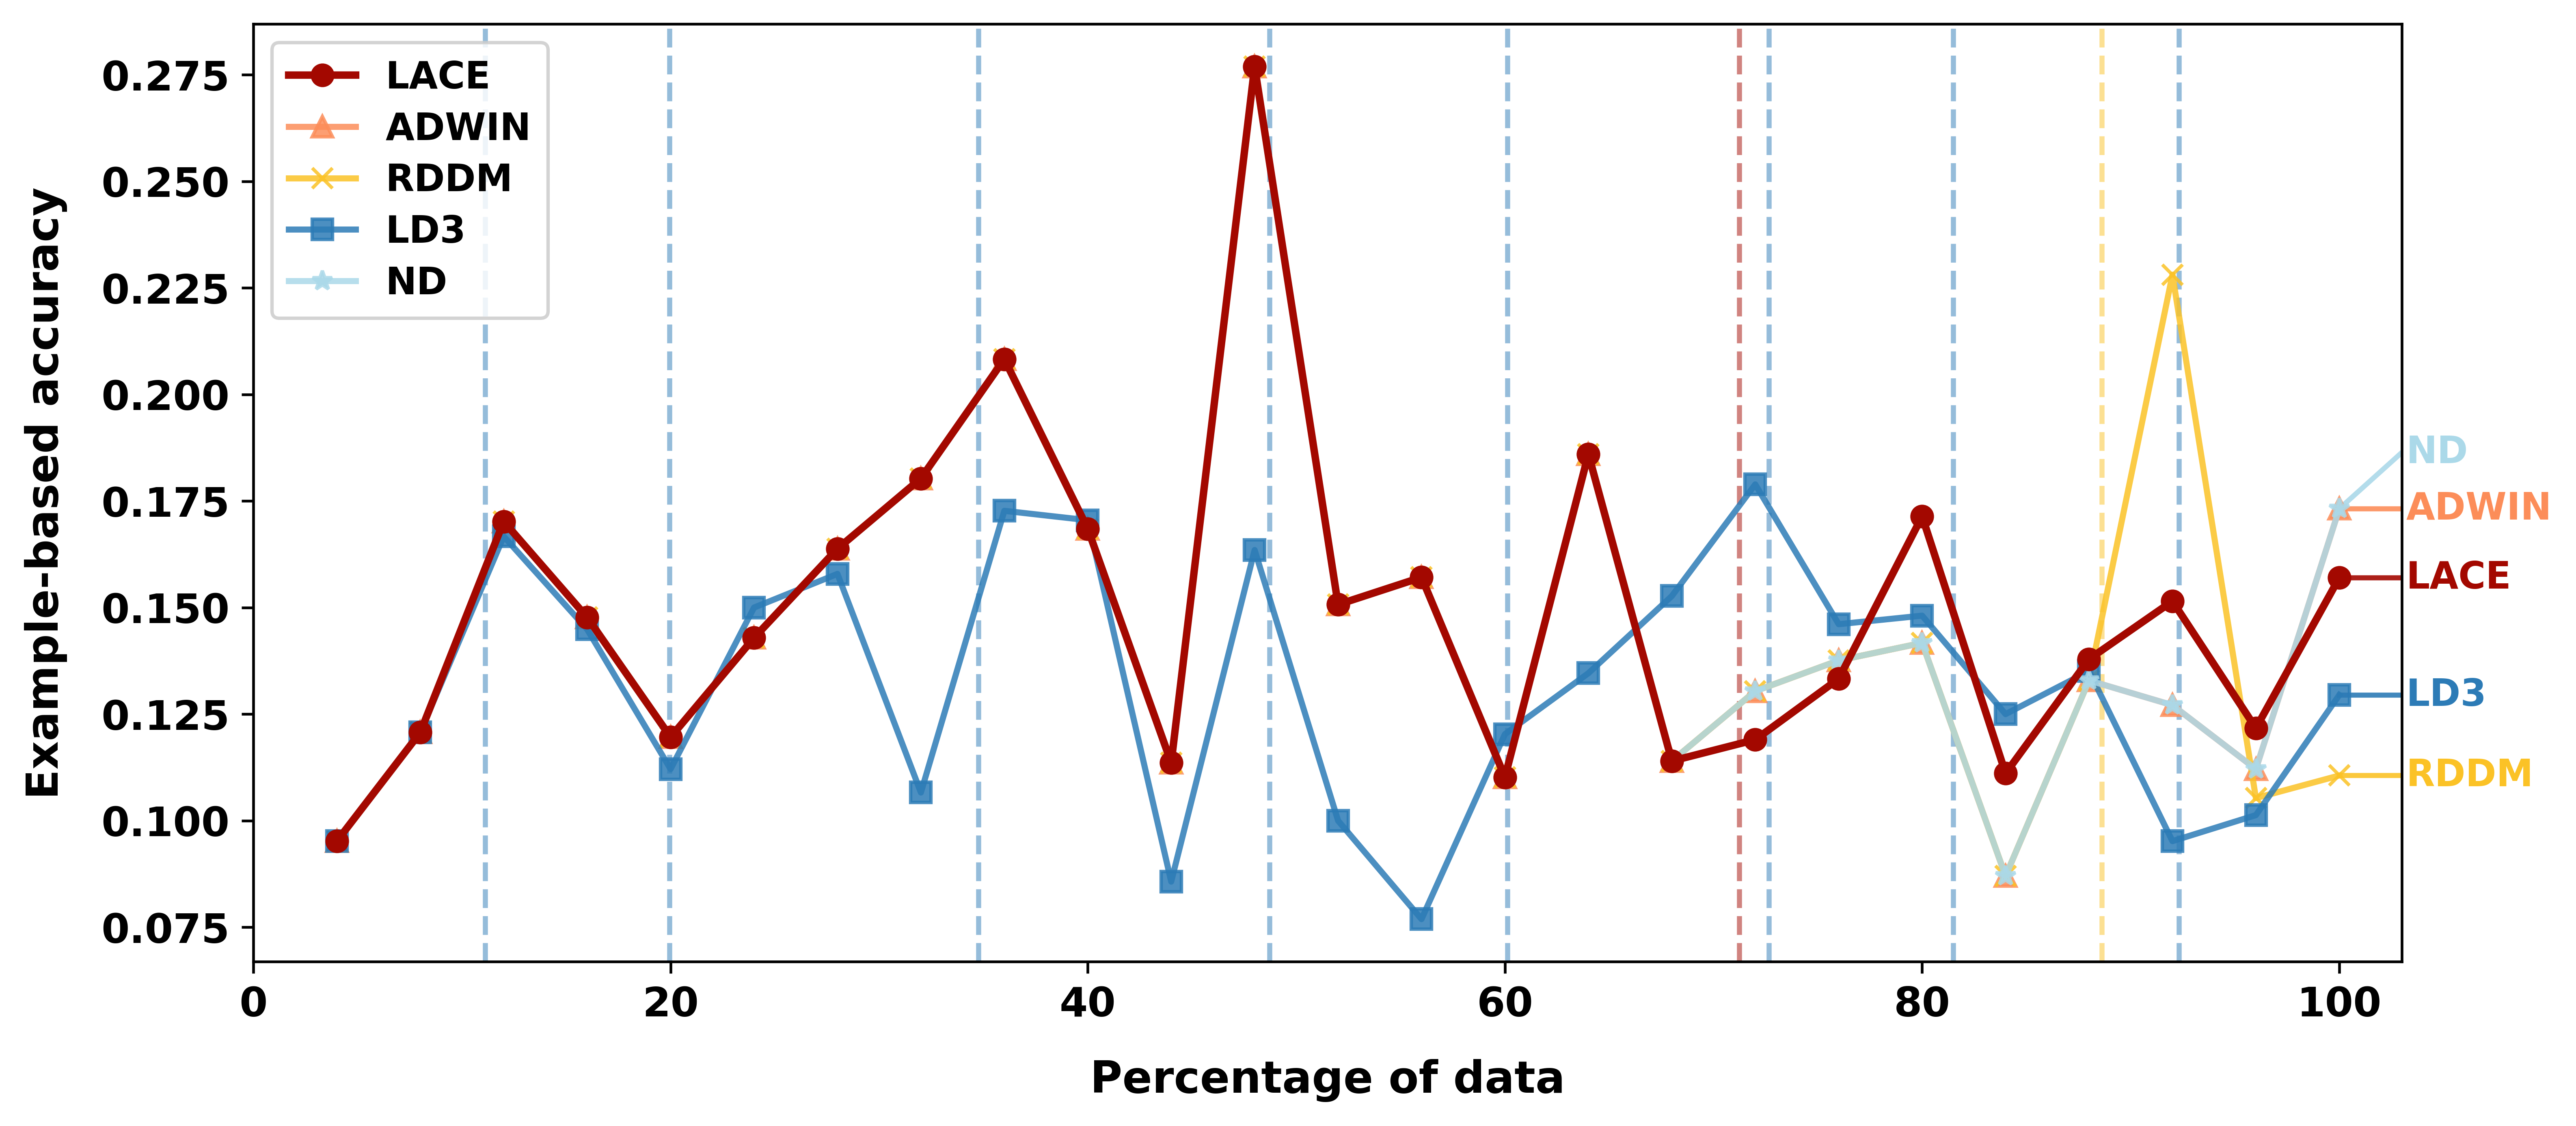

Dataset: Plant
Loading predictions from outputs/predictions/Plant
Loading dataset Plant to get true labels...
Loaded 978 true labels before zero-label filtering
Loaded predictions for 5 detectors
Loaded 978 true labels after zero-label filtering
Plotting results for Plant...
  Plot(s) will be saved to /Users/mehmetkadrigofralilar/Desktop/LACE/outputs/plots


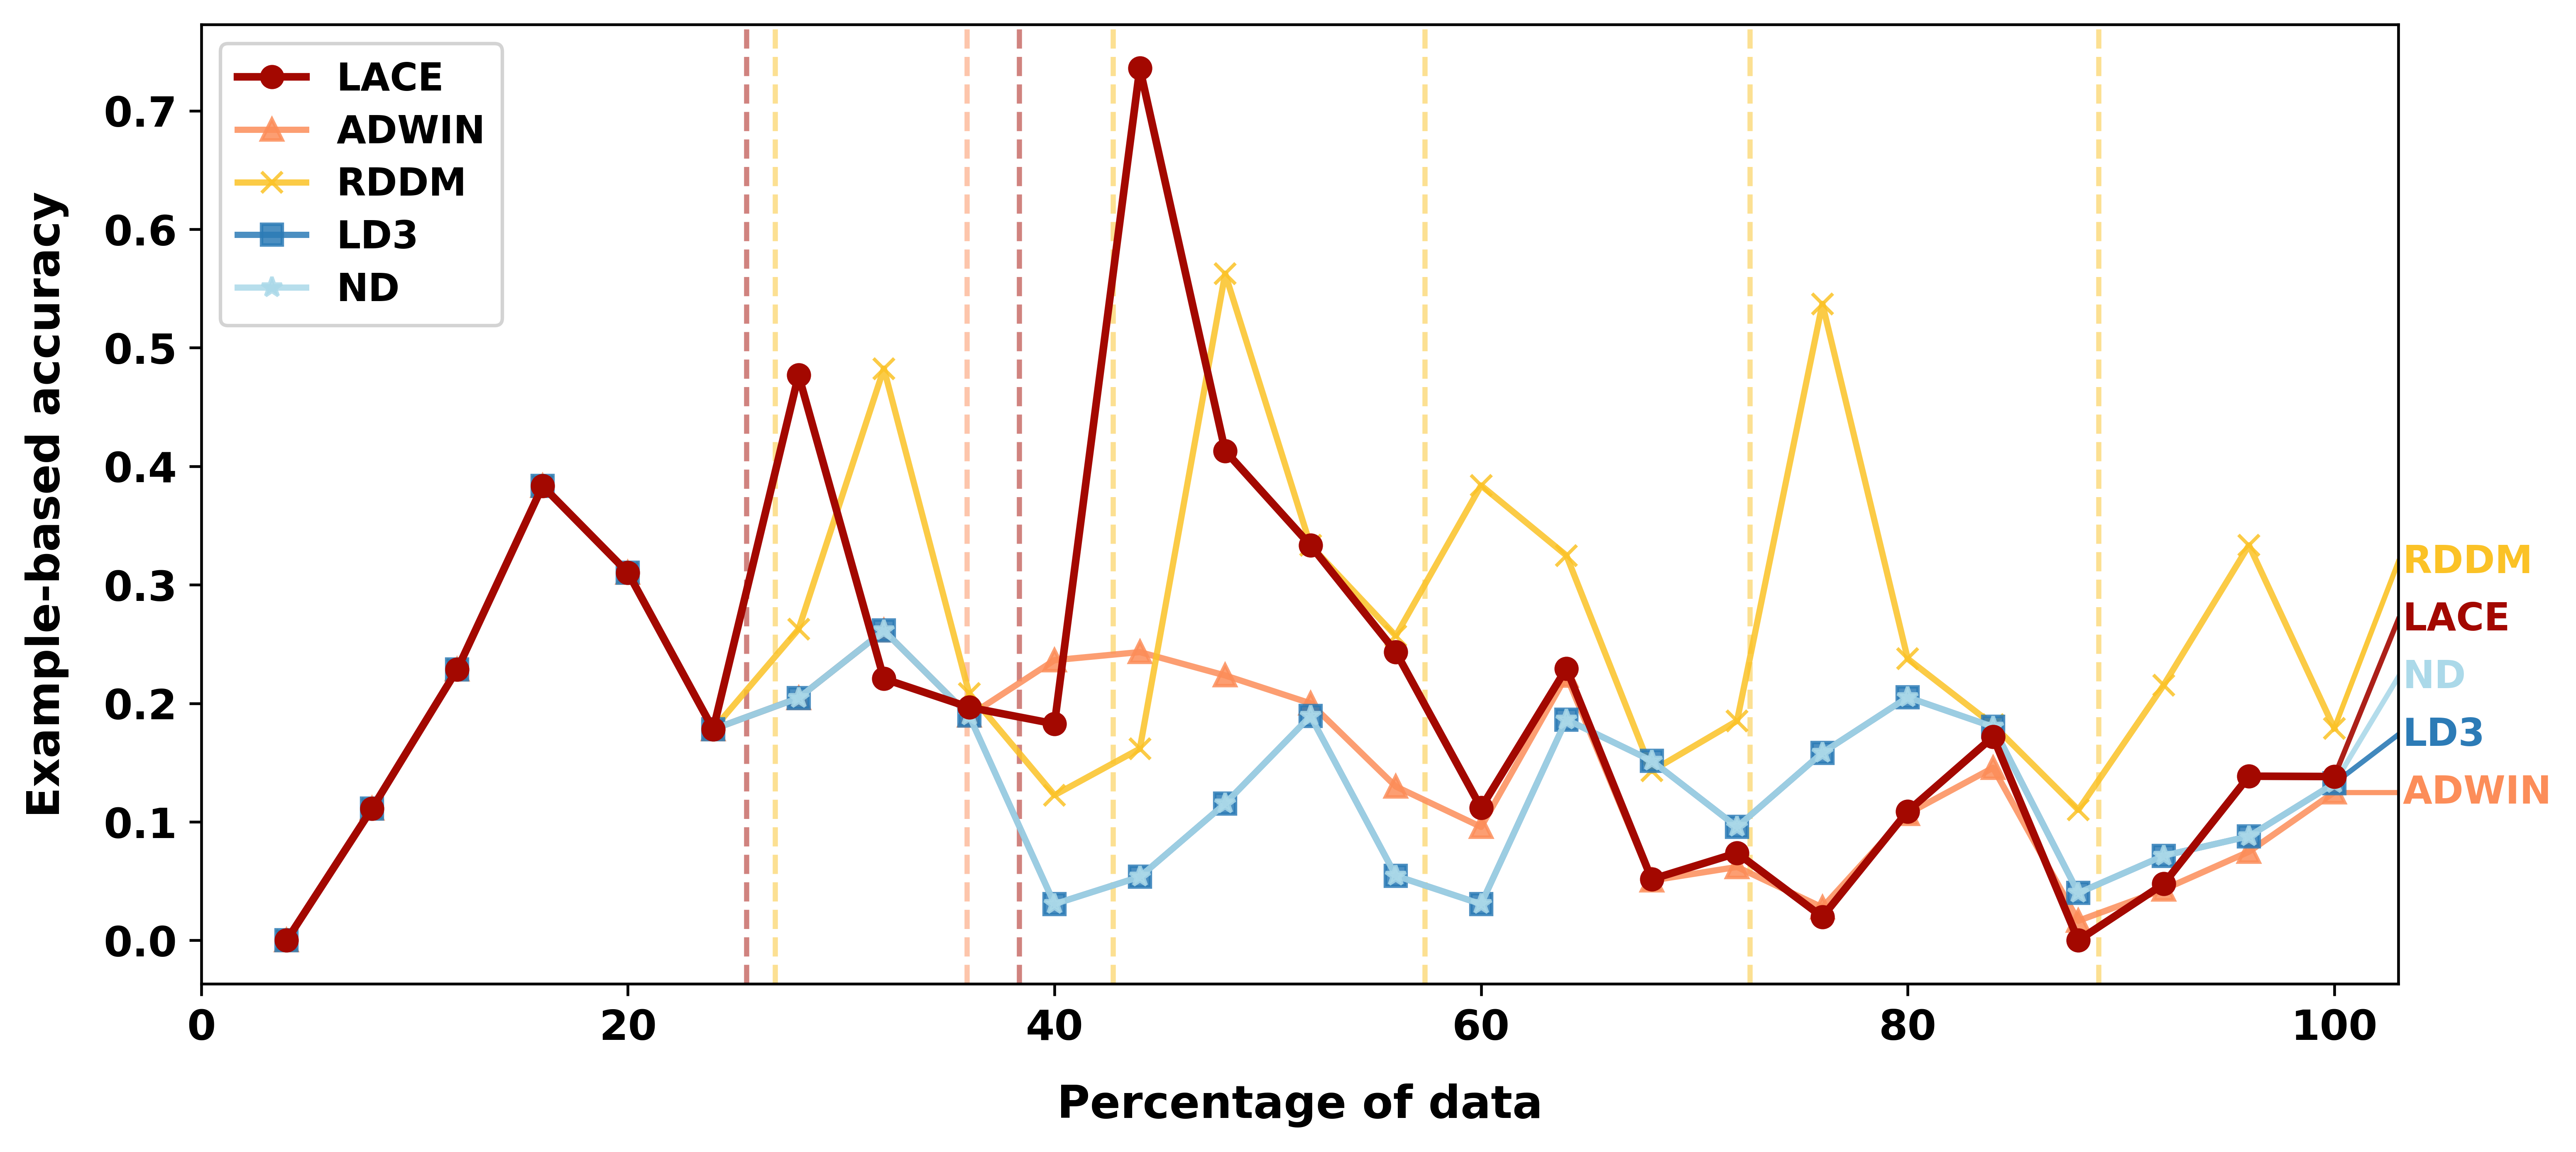

Dataset: Enron
Loading predictions from outputs/predictions/Enron
Loading dataset Enron to get true labels...
Loaded 1702 true labels before zero-label filtering
Loaded predictions for 5 detectors
Loaded 1702 true labels after zero-label filtering
Plotting results for Enron...
  Plot(s) will be saved to /Users/mehmetkadrigofralilar/Desktop/LACE/outputs/plots


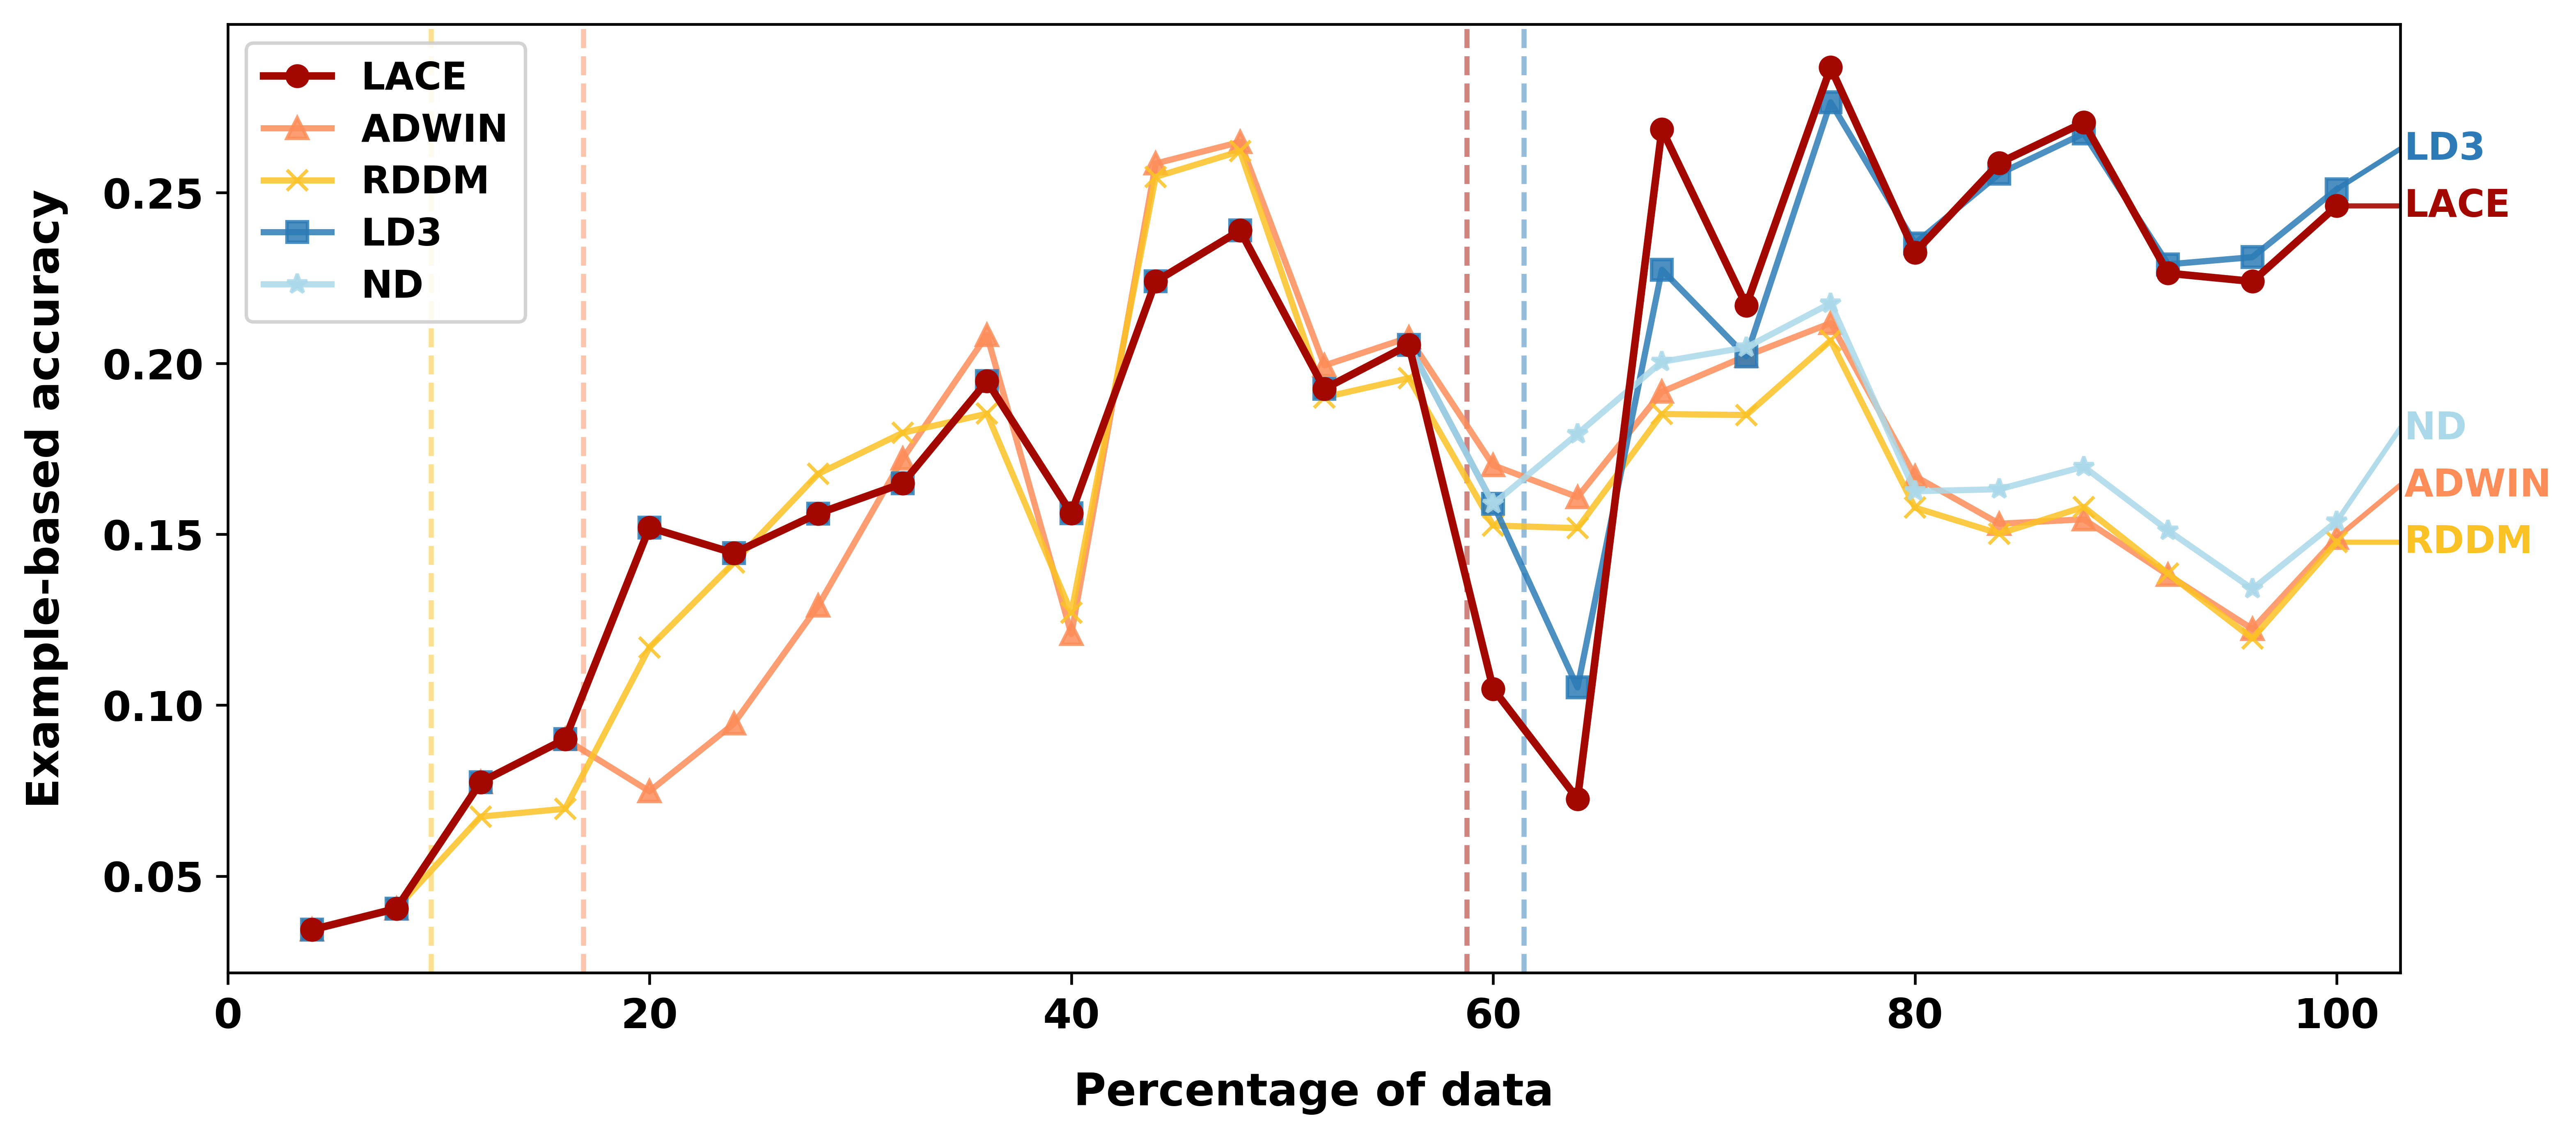

Dataset: Human
Loading predictions from outputs/predictions/Human
Loading dataset Human to get true labels...
Loaded 3106 true labels before zero-label filtering
Loaded predictions for 5 detectors
Loaded 3106 true labels after zero-label filtering
Plotting results for Human...
  Plot(s) will be saved to /Users/mehmetkadrigofralilar/Desktop/LACE/outputs/plots


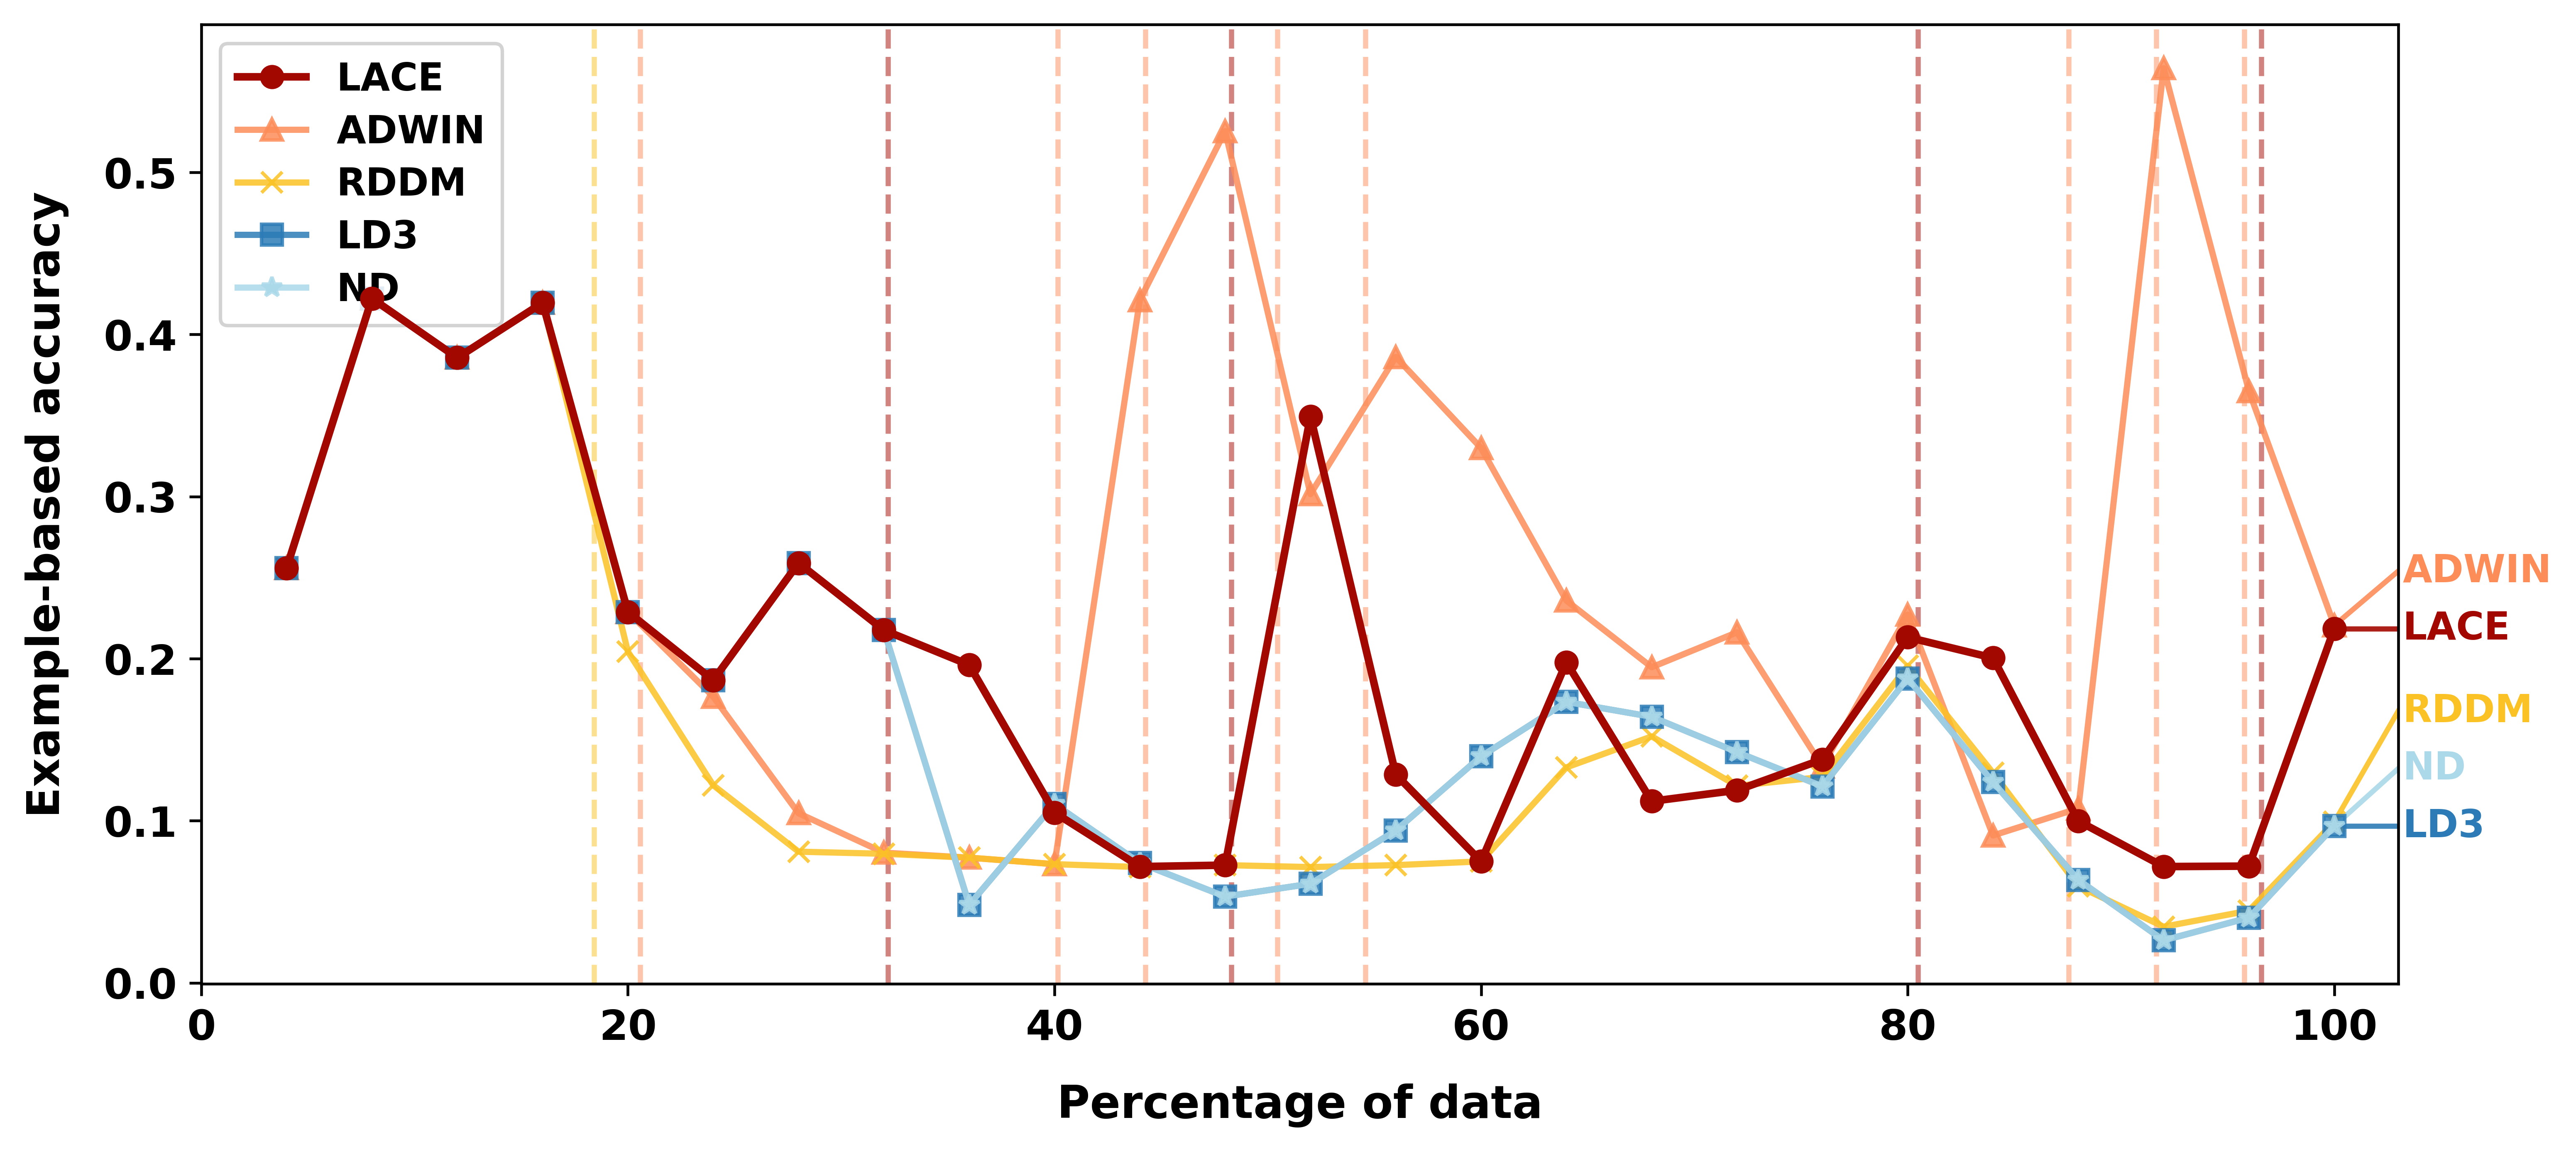

Dataset: Synthetic_Incremental1
Loading predictions from outputs/predictions/Synthetic_Incremental1
Generating synthetic stream gradual1 to get true labels...
Loaded 20000 true labels before zero-label filtering
Loaded predictions for 5 detectors
Loaded 17981 true labels after zero-label filtering
Plotting results for Synthetic_Incremental1...
  Plot(s) will be saved to /Users/mehmetkadrigofralilar/Desktop/LACE/outputs/plots


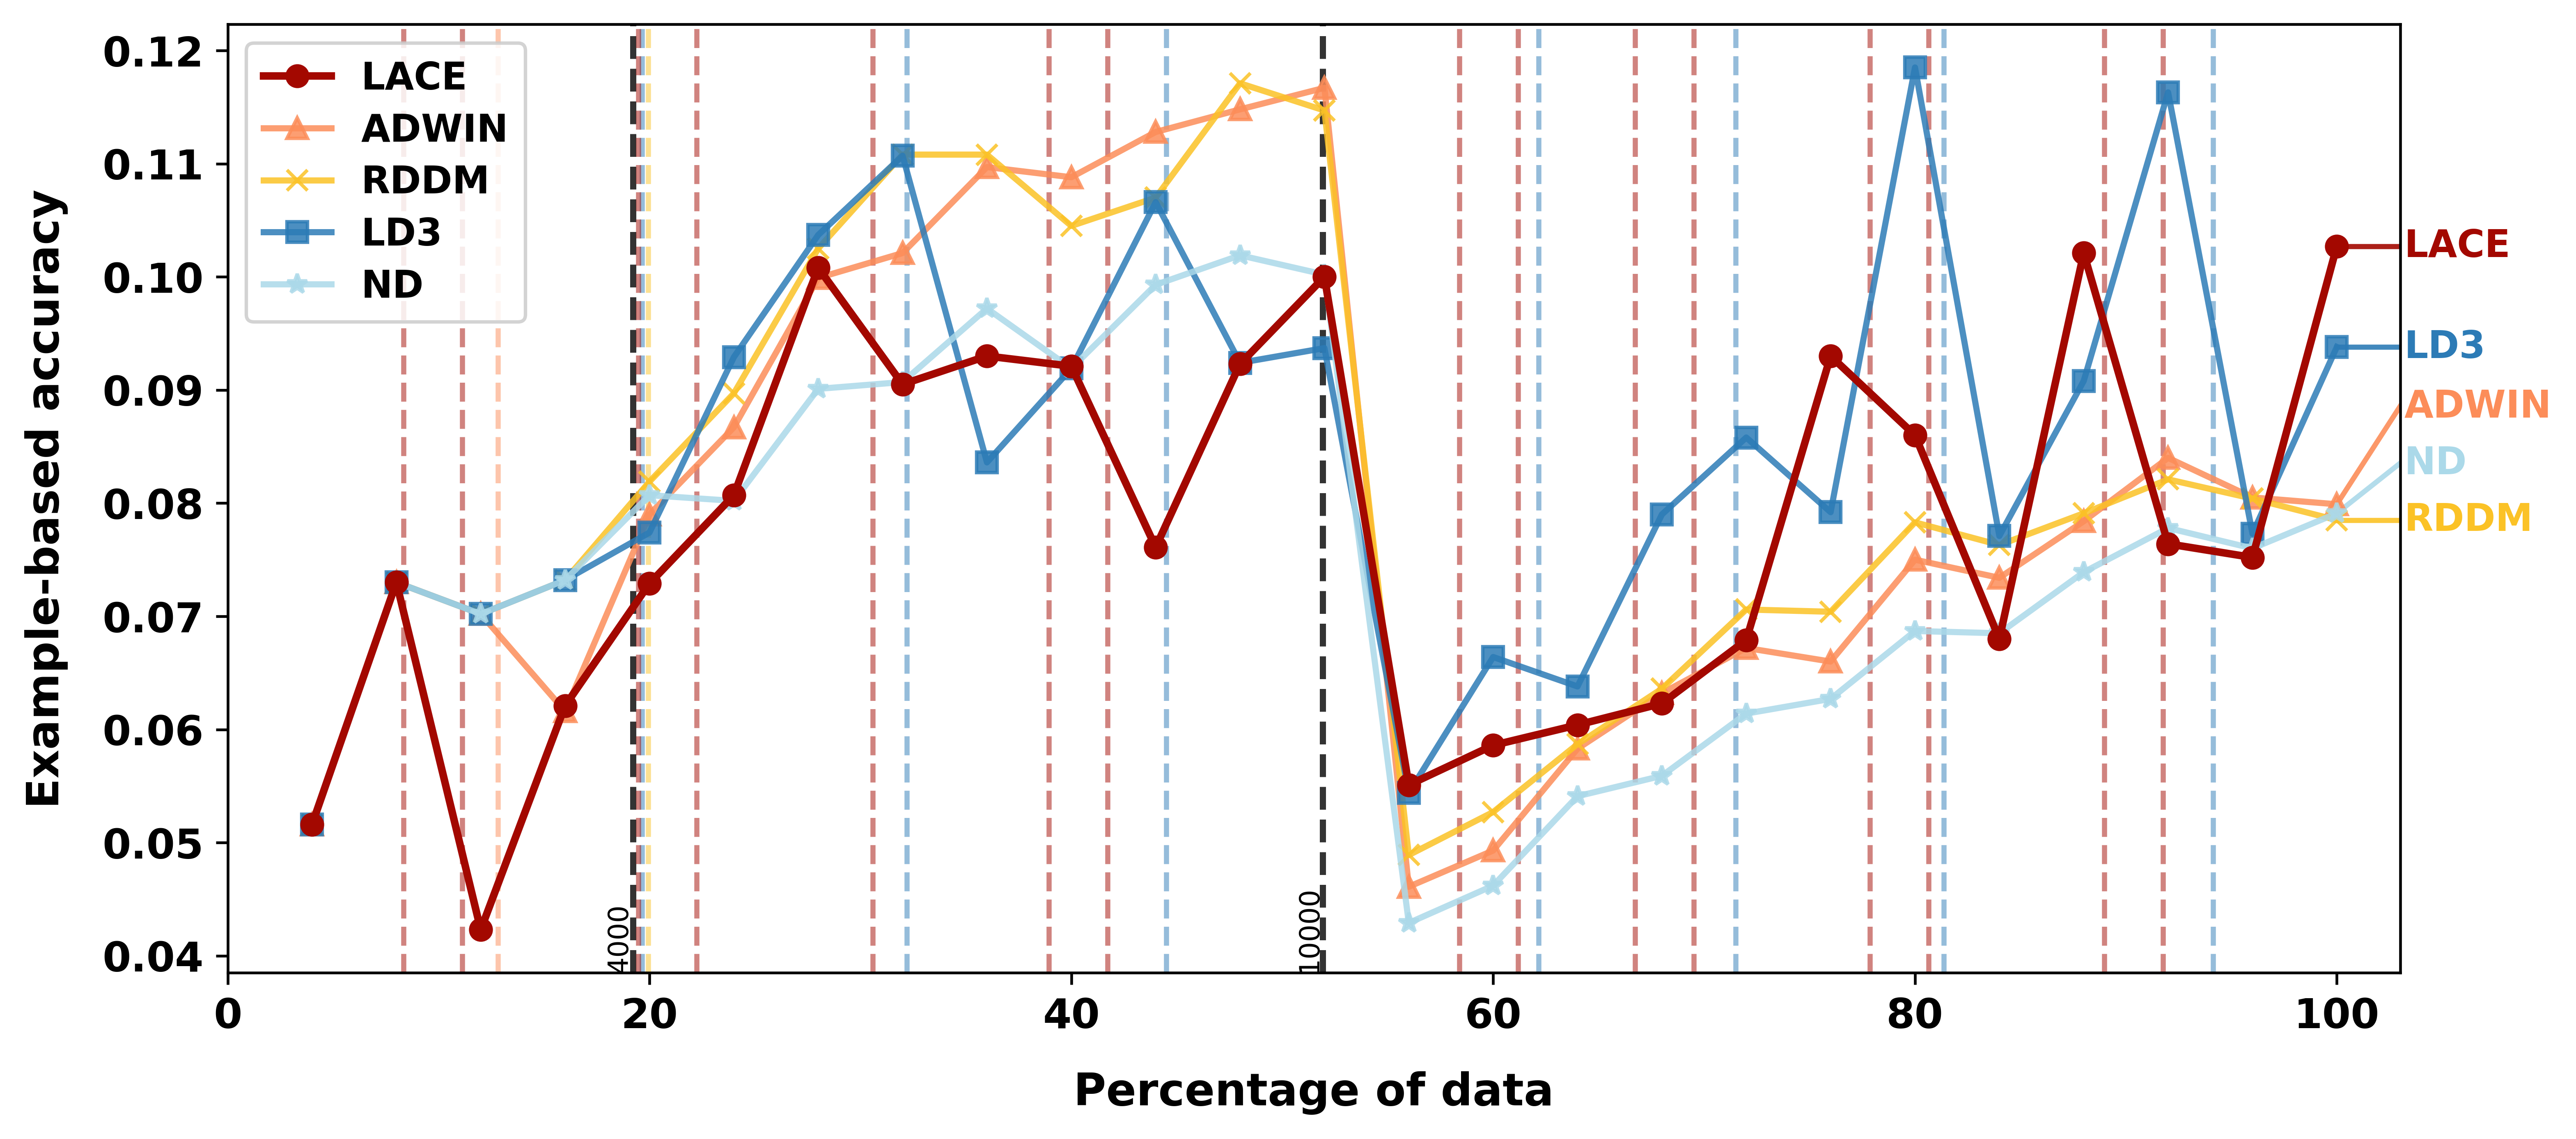

'\n    util.plot_detector_metrics(\n        results_by_name,\n        results_true,\n        dataset_name,\n        metrics_to_plot,\n        save_plots=True,\n        drift_points_by_name=drift_points_by_name,\n        top_method="LACE",\n        processed_stream_indices=processed_stream_indices,\n        legend_position=\'top\',\n        cumulative=True\n    )\n'

In [8]:
dataset_specs_names = sorted(dataset_specs, key=lambda x: dataset_specs[x]["n_instances"])
for dataset_name in dataset_specs_names:   
    if dataset_name not in ["Synthetic_Incremental1", "Birds", "Enron", "Human", "Plant"]:
        continue

    
    # Load predictions, true labels, and detector drift points
    #results_by_name, results_true, DATA_TYPE, drift_points_by_name = util.load_predictions_and_labels(dataset_name, dataset_specs)
    # get the correct c3m variant for the dataset from info
    print(f"Dataset: {dataset_name}")
    #if dataset_name != 'Imdb':
        #continue
    #methods_to_plot = ["LACE", "LACE-KMeans_Variant", "LACE-Agglomerative_Variant"]
    methods_to_plot = None
    methods_to_plot = ["LD3", "ADWIN", "RDDM", "ND", "LACE"]
    
    label_location  = 'start'
    #results_by_name, results_true, DATA_TYPE, drift_points_by_name = util.load_predictions_and_labels(dataset_name, dataset_specs, filter_methods=methods_to_plot, label_location=label_location)
    results_by_name, results_true, DATA_TYPE, drift_points_by_name, processed_stream_indices = util.load_predictions_and_labels(
    dataset_name,
    dataset_specs,
    filter_methods=methods_to_plot,
    label_location=label_location
)
    # Plot detector metrics with drift lines
    legend_position = 'bottom' if dataset_name in ['Human'] else 'top'
    util.plot_detector_metrics(
        results_by_name,
        results_true,
        dataset_name,
        metrics_to_plot,
        save_plots=True,
        drift_points_by_name=drift_points_by_name,
        top_method="LACE",
        processed_stream_indices=processed_stream_indices,
        legend_position='top',
        cumulative=False
    )

"""
    util.plot_detector_metrics(
        results_by_name,
        results_true,
        dataset_name,
        metrics_to_plot,
        save_plots=True,
        drift_points_by_name=drift_points_by_name,
        top_method="LACE",
        processed_stream_indices=processed_stream_indices,
        legend_position='top',
        cumulative=True
    )
"""

# Nemenyi and Holm

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from autorank import autorank, plot_stats
from scipy.stats import friedmanchisquare, norm
from statsmodels.stats.multitest import multipletests
from autorank._util import cd_diagram
from matplotlib.transforms import Bbox

In [71]:
base_path = '/Users/mehmetkadrigofralilar/Desktop/LACE/outputs/tables_figures/effectiveness'
save_path = '/Users/mehmetkadrigofralilar/Desktop/LACE/outputs/tables_figures/nemenyi'

In [72]:
metrics = ['accuracies', 'hamming_scores', 'f1_example_scores', 'f1_micro_scores', 'f1_macro_scores']

In [73]:
label_shifts = {
    'accuracies': {
        'left': 0.10,
        'right': 0.10
    },
    'hamming_scores': {
        'left': 0.10,
        'right': 0.14
    },
    'f1_example_scores': {
        'left': 0.125,
        'right': 0.085
    },
    'f1_micro_scores': {
        'left': 0.09,
        'right': 0.085
    },
    'f1_macro_scores': {
        'left': 0.125,
        'right': 0.09
    }
}

Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
             meanrank  median     mad ci_lower ci_upper effect_size  \
DDM         14.100000  0.0965  0.0335   0.0561   0.3979         0.0   
EDDM        11.633333  0.1365  0.0383   0.0681   0.4075   -0.749848   
HDDM_A      11.000000  0.1651  0.0292   0.0726   0.4089   -1.472461   
HDDM_W      10.366667  0.1729  0.0406   0.0726   0.4089   -1.384512   
KSWIN       10.366667  0.1938  0.0259   0.0726   0.4089   -2.191828   
SeqDrift2   10.166667  0.1874  0.0362   0.0726   0.4089    -1.75797   
FHDDMS       9.866667  0.1938  0.0259   0.0726   0.4089   -2.191828   
FHDDM        9.333333  0.1942  0.0263   0.0726   0.4089   -2.188135   
FHDDMS_add   9.133333  0.1942  0.0263   0.0726   0.4089   -2.188135   
MDDM_G       8.733333  0.1938  0.0259   0.0726   0.4236   -2.191828   
MDDM_E       8.666667  0.1938  0.0259   0.0726   0.4238   -2.191828   
MDDM_A       8.533333  0.1942  0.0263   0.0726   0

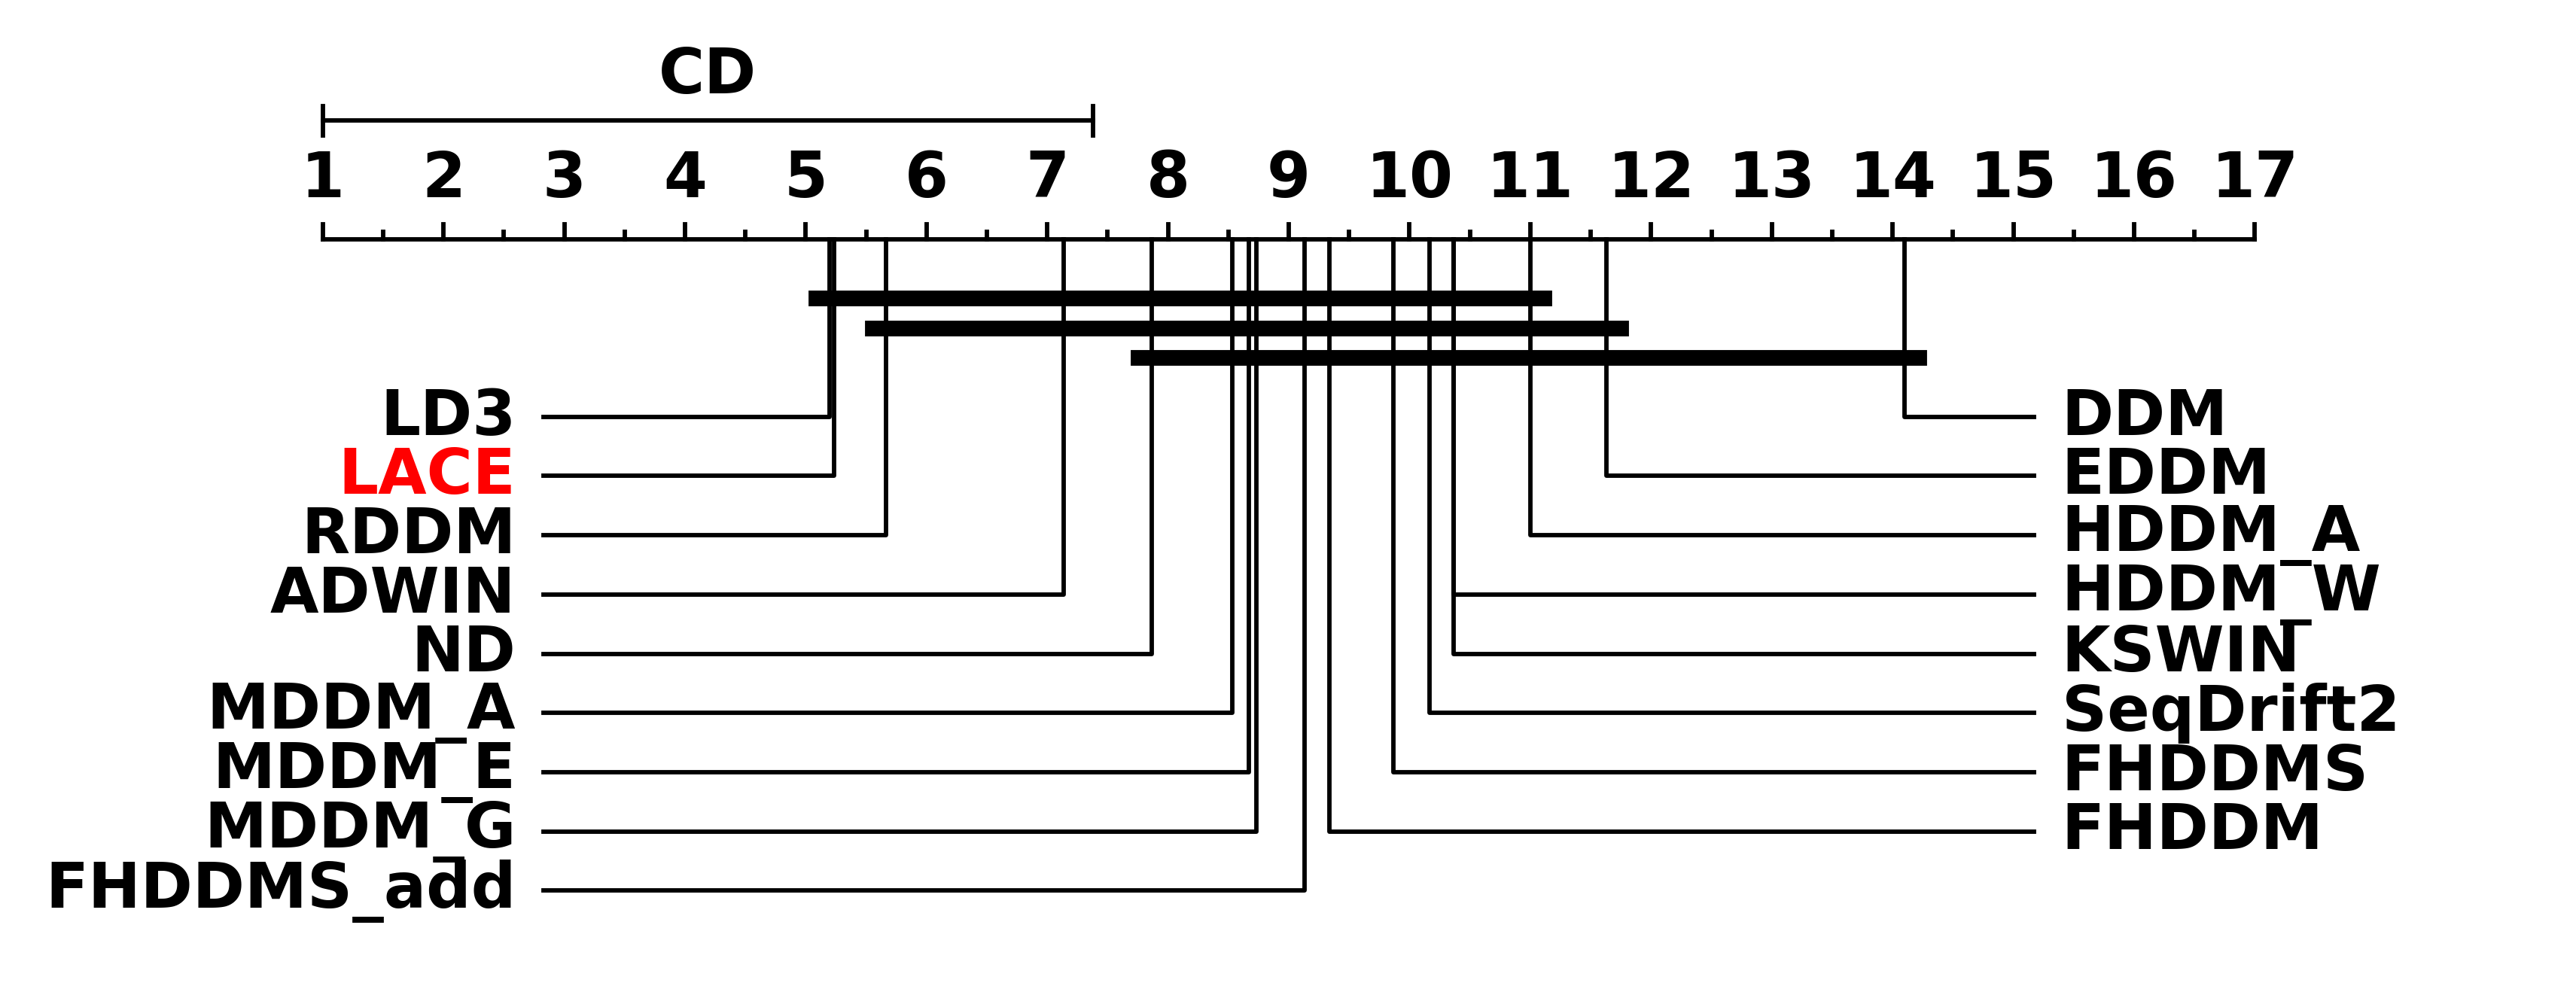

Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
             meanrank  median     mad  ci_lower  ci_upper effect_size  \
DDM         15.033333  0.1480   0.075  0.060567  0.289433         0.0   
FHDDMS      10.466667  0.1905  0.0473  0.102792  0.323902   -0.316155   
HDDM_A      10.400000  0.1860  0.0568  0.097717  0.307603   -0.233698   
EDDM        10.100000  0.1710  0.0677  0.075638  0.308975   -0.138927   
SeqDrift2    9.833333  0.1860  0.0687  0.099395  0.317992   -0.279318   
HDDM_W       9.500000  0.1905  0.0506  0.105936  0.310851   -0.285204   
FHDDM        9.466667  0.1905  0.0473  0.102615  0.333905    -0.34882   
MDDM_A       9.366667  0.1905  0.0473  0.102072  0.334502   -0.348167   
FHDDMS_add   9.300000  0.1905  0.0473  0.101424  0.334709   -0.345751   
MDDM_E       9.200000  0.1905  0.0473  0.101764  0.333196   -0.342424   
MDDM_G       9.000000  0.1905  0.0473  0.101209  0.335204   -0.346338   
KSWIN        8.766667  0.1

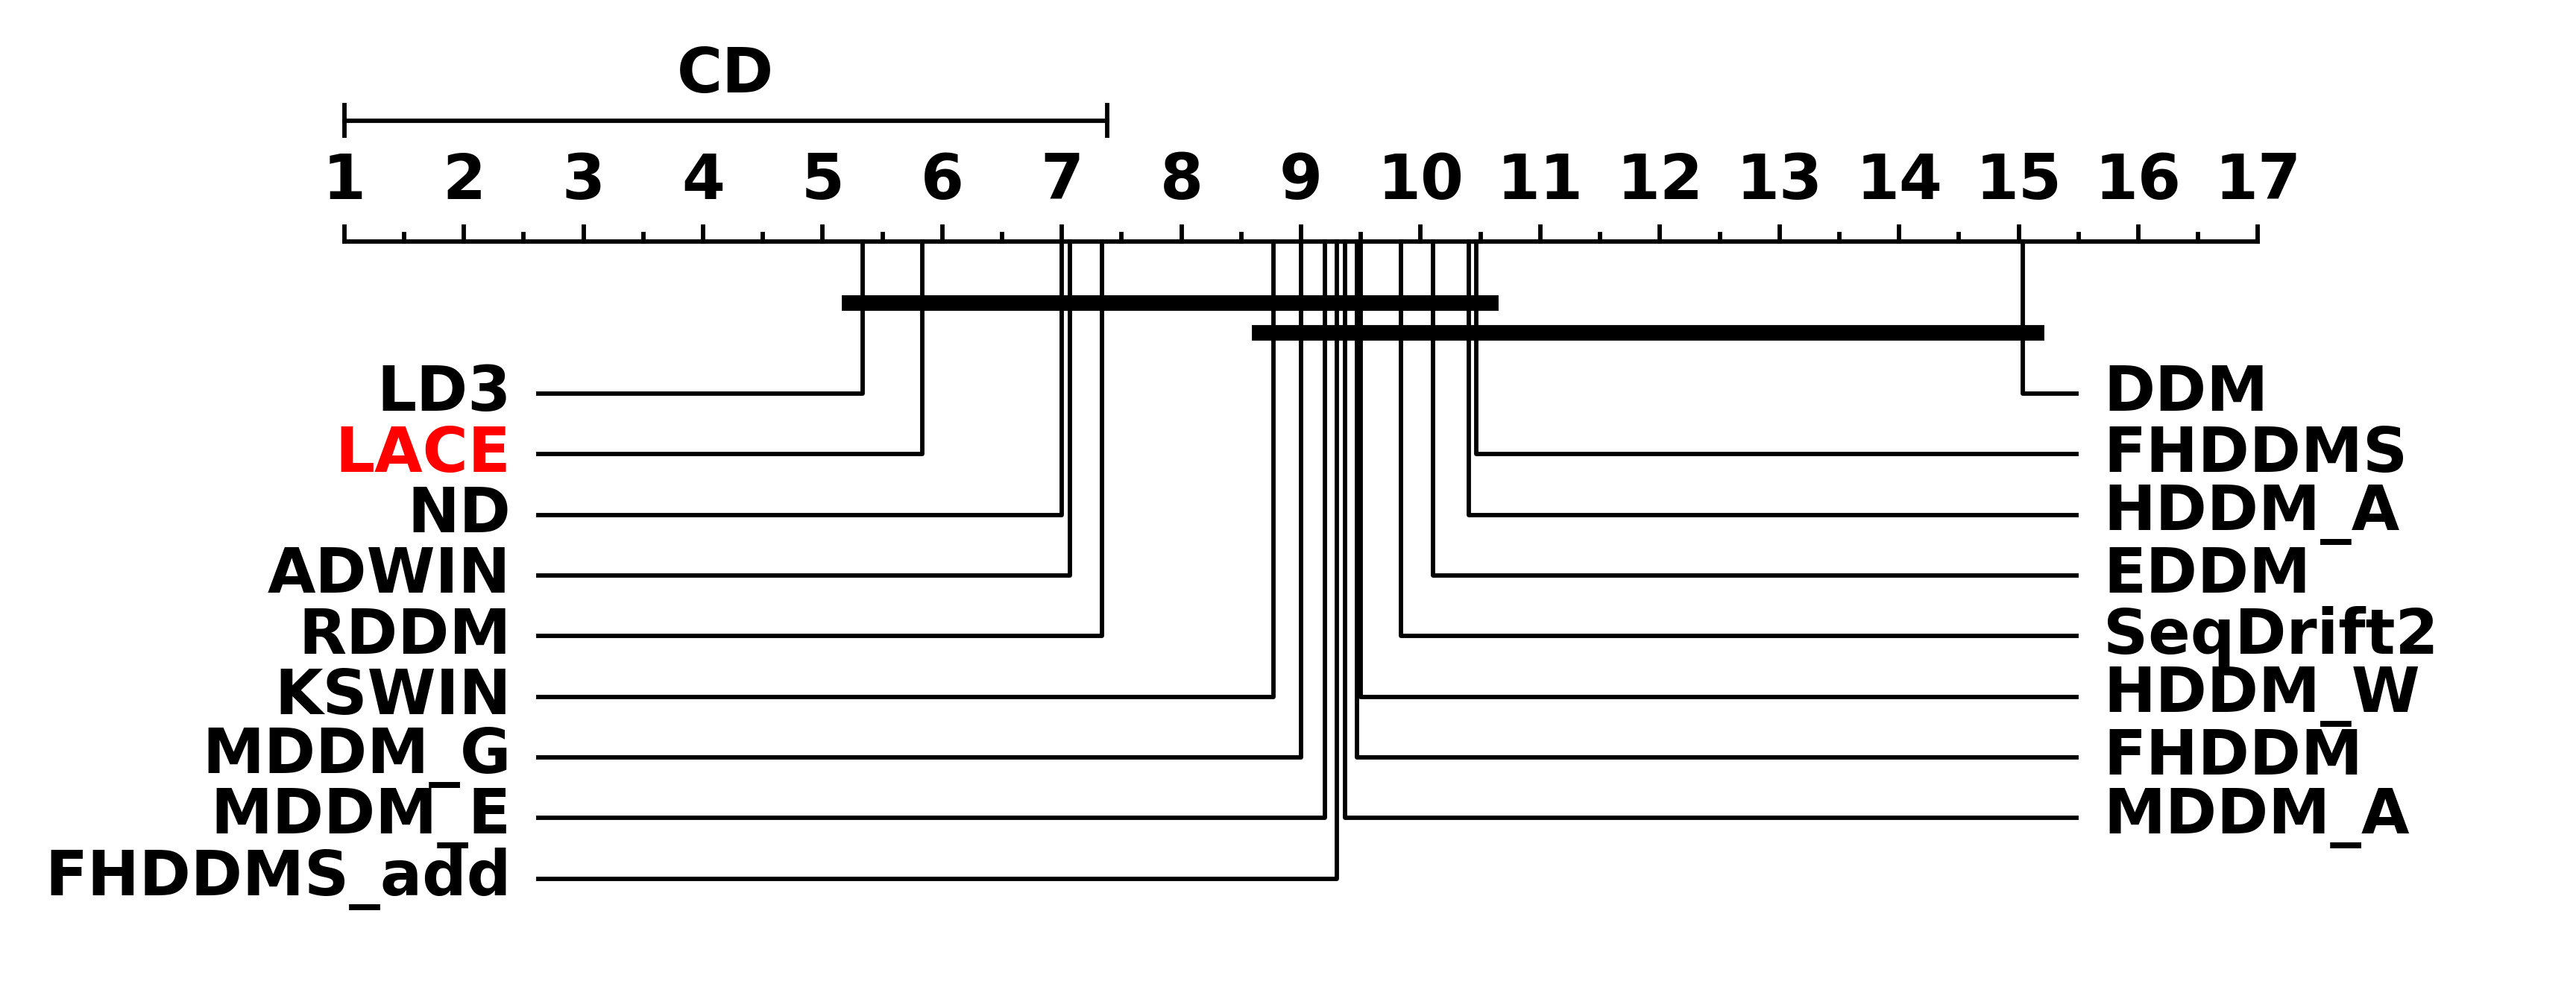

Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
             meanrank  median     mad  ci_lower  ci_upper effect_size  \
DDM         14.900000  0.1199  0.0614  0.052396  0.232604         0.0   
EDDM        11.700000  0.1255  0.0674  0.059988  0.236812   -0.061313   
LD3         10.666667  0.1187   0.055  0.066679  0.257575   -0.196154   
RDDM        10.100000  0.1432  0.0572  0.065158  0.284989   -0.300654   
ADWIN       10.000000  0.1158  0.0503  0.067526   0.27606   -0.278859   
HDDM_A       9.600000  0.1221  0.0526  0.067092  0.249028   -0.159423   
SeqDrift2    8.766667  0.1186  0.0491  0.067968  0.263899   -0.230958   
FHDDMS       8.733333  0.1186  0.0491  0.067158  0.262882   -0.222083   
HDDM_W       8.433333  0.1327  0.0551  0.069119  0.249734   -0.174062   
FHDDM        8.033333  0.1186  0.0491  0.068093  0.265041   -0.236535   
FHDDMS_add   7.666667  0.1186  0.0491  0.064499  0.273421   -0.251619   
MDDM_G       7.600000  0.1

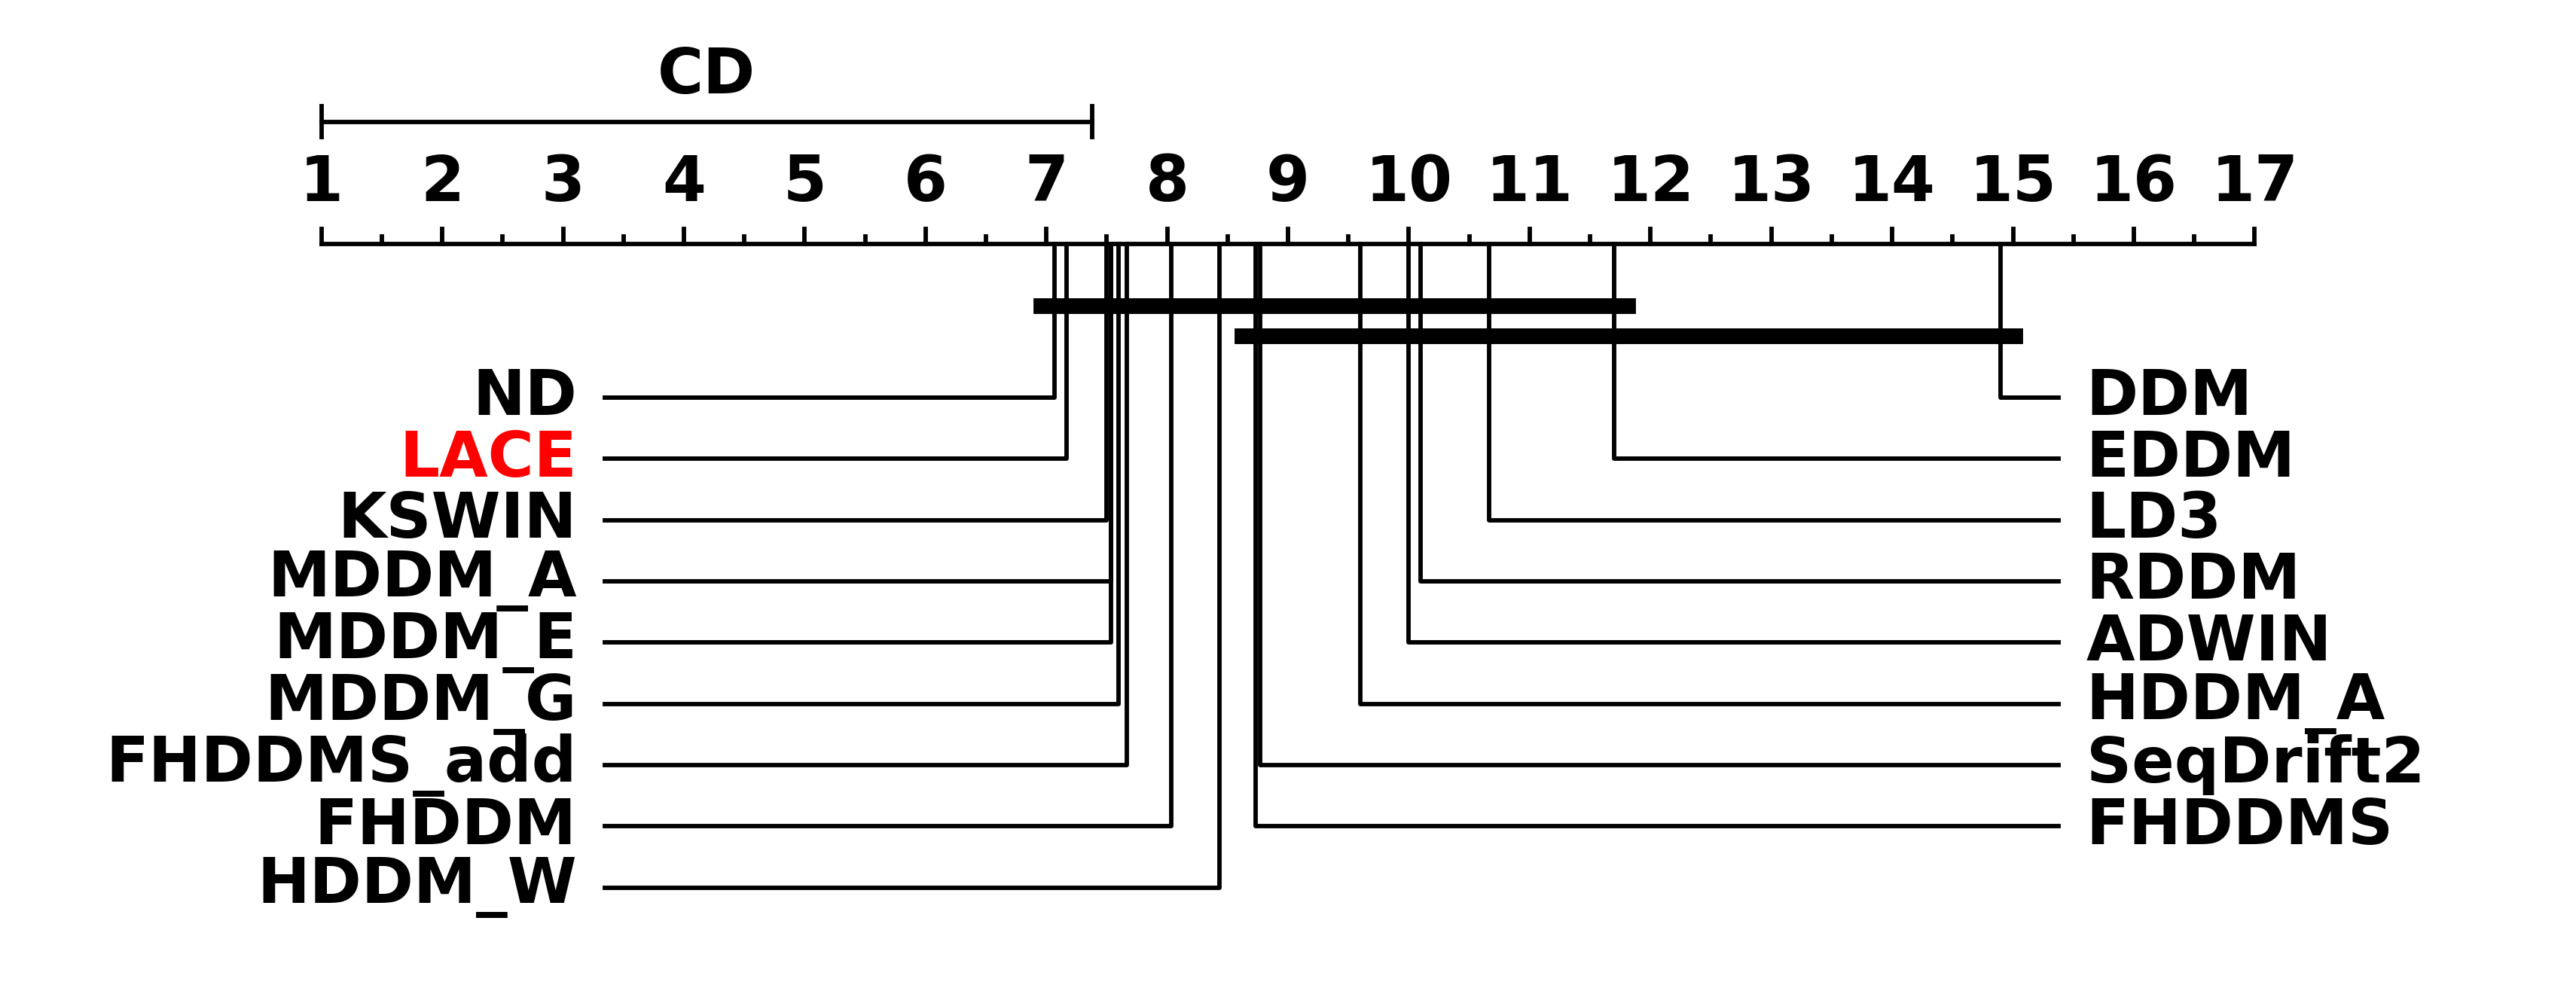

In [75]:
for metric in metrics:
    df_accuracy = pd.read_csv(f'{base_path}/{metric}.csv')

    df_accuracy = df_accuracy.set_index('Dataset')

    df_accuracy = df_accuracy.drop(columns=[col for col in df_accuracy.columns if 'LACE-' in col])

    df_no_synth_accuracy = df_accuracy[~df_accuracy.index.str.contains('Synthetic')]

    result_no_synth = autorank(
        df_no_synth_accuracy,
        alpha=0.05,
        verbose=False,
        order='descending',
        force_mode='nonparametric',
    )

    fig = plt.figure(figsize=(5, 2))

    ax = fig.add_axes([0, 0, 1.10, 1])

    cd_diagram(result_no_synth, reverse=False, ax=ax, width=9)

    # Move method names closer to the center
    label_shift_left = label_shifts[metric]['left']
    label_shift_right = label_shifts[metric]['right']

    for text in ax.texts:
        label = text.get_text().strip()

        # Skip CD label and rank numbers
        if label == "CD" or label.replace(".", "", 1).isdigit():
            continue

        if text.get_ha() == "right":
            x, y = text.get_position()
            text.set_position((x + label_shift_left, y))

        elif text.get_ha() == "left":
            x, y = text.get_position()
            text.set_position((x - label_shift_right, y))

    for line in ax.lines:
        xdata = list(line.get_xdata())
        ydata = list(line.get_ydata())
        if len(xdata) == 3 and len(ydata) == 3:
            if xdata[-1] < xdata[0]:
                xdata[-1] += label_shift_left
            elif xdata[-1] > xdata[0]:
                xdata[-1] -= label_shift_right
            line.set_xdata(xdata)
        #line.set_linewidth(0.7)

    highlight_colors = {
        'LACE': 'red'
    }

    for text in ax.texts:
        label = text.get_text().strip()
        if label in highlight_colors:
            text.set_color(highlight_colors[label])
        text.set_fontweight('bold')
    print(f"Plotted Nemenyi diagram for {metric}")
    
    metric = metric.replace('_scores', '').replace('accuracies', 'accuracy')

    plt.savefig(
      f'{save_path}/nemenyi_{metric}.pdf',
      dpi=600,
      bbox_inches=Bbox.from_extents(0, 0.05, 5.25, 2.05),
      pad_inches=0.0
    )
    plt.show()


#### Testing Cumulative Nemenyi

Combined dataframe shape: (45, 17)
Number of evaluation blocks: 45
Methods: ['SeqDrift2', 'MDDM_E', 'ADWIN', 'DDM', 'KSWIN', 'MDDM_A', 'EDDM', 'ND', 'HDDM_A', 'HDDM_W', 'LD3', 'FHDDMS', 'FHDDM', 'MDDM_G', 'RDDM', 'FHDDMS_add', 'LACE']
Tests for normality and homoscedacity are ignored for test selection, forcing nonparametric tests
             meanrank  median     mad ci_lower ci_upper effect_size  \
DDM         14.677778  0.1199  0.0569   0.0697   0.2409         0.0   
EDDM        11.144444  0.1517  0.0535   0.0776   0.2506   -0.388381   
HDDM_A      10.333333  0.1651  0.0526    0.086   0.2411   -0.556411   
FHDDMS       9.688889  0.1882  0.0624    0.086   0.2691   -0.771481   
SeqDrift2    9.588889  0.1844  0.0671    0.086   0.2691   -0.699326   
HDDM_W       9.433333  0.1767  0.0546    0.086   0.2439   -0.687048   
FHDDM        8.944444  0.1907  0.0599    0.086   0.2691   -0.817435   
KSWIN        8.877778  0.1903  0.0576    0.086   0.2691   -0.829402   
FHDDMS_add   8.700000  0.190

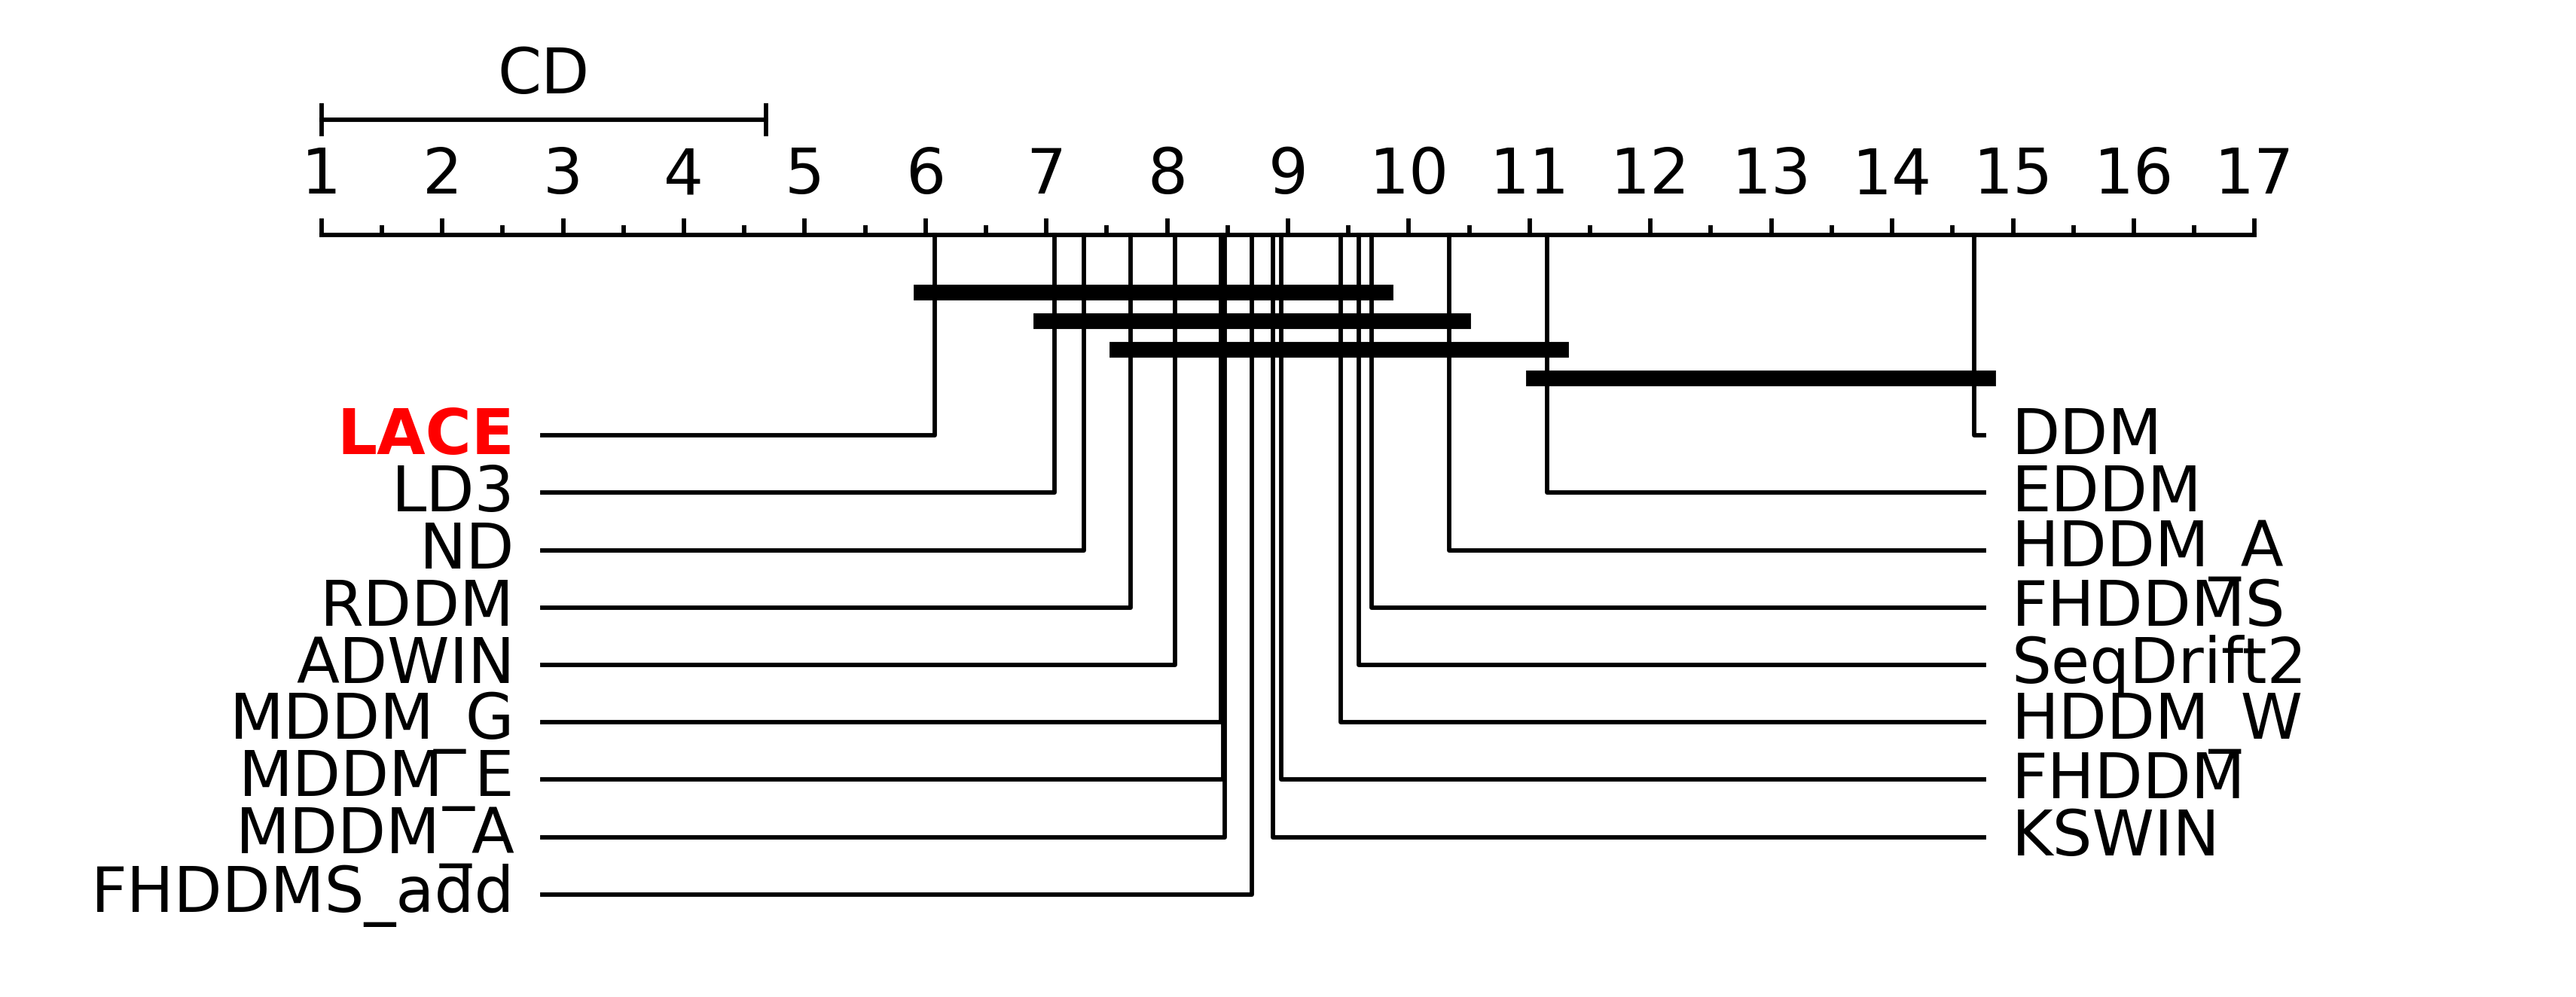

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from autorank import autorank
from autorank._util import cd_diagram
from matplotlib.transforms import Bbox


base_path = '/Users/mehmetkadrigofralilar/Desktop/LACE/outputs/tables_figures/effectiveness'
save_path = '/Users/mehmetkadrigofralilar/Desktop/LACE/outputs/tables_figures/nemenyi'

"""
    'hamming_scores',
"""
metrics = [
    'accuracies',
    'f1_micro_scores',
    'f1_macro_scores'
]

combined_rows = []

for metric in metrics:
    df_metric = pd.read_csv(f'{base_path}/{metric}.csv')
    df_metric = df_metric.set_index('Dataset')
    # Each row becomes one evaluation block: dataset + metric.
    df_metric.index = [f'{dataset}__{metric}' for dataset in df_metric.index]

    combined_rows.append(df_metric)

df_combined = pd.concat(combined_rows, axis=0)

# Keep only methods available in all metric tables.
df_combined = df_combined.dropna(axis=1, how='any')

print("Combined dataframe shape:", df_combined.shape)
print("Number of evaluation blocks:", len(df_combined))
print("Methods:", list(df_combined.columns))

result_combined = autorank(
    df_combined,
    alpha=0.05,
    verbose=False,
    order='descending',
    force_mode='nonparametric',
)



fig = plt.figure(figsize=(5, 2))
ax = fig.add_axes([0, 0, 1.10, 1])


cd_diagram(result_combined, reverse=False, ax=ax, width=9)

# Move method names closer to the center.
label_shift_left = 0.10
label_shift_right = 0.12

for text in ax.texts:
    label = text.get_text().strip()

    # Skip CD label and rank numbers.
    if label == "CD" or label.replace(".", "", 1).isdigit():
        continue

    if text.get_ha() == "right":
        x, y = text.get_position()
        text.set_position((x + label_shift_left, y))

    elif text.get_ha() == "left":
        x, y = text.get_position()
        text.set_position((x - label_shift_right, y))

for line in ax.lines:
    xdata = list(line.get_xdata())
    ydata = list(line.get_ydata())

    if len(xdata) == 3 and len(ydata) == 3:
        if xdata[-1] < xdata[0]:
            xdata[-1] += label_shift_left
        elif xdata[-1] > xdata[0]:
            xdata[-1] -= label_shift_right

        line.set_xdata(xdata)

# Highlight LACE.
highlight_colors = {
    'LACE': 'red'
}

for text in ax.texts:
    label = text.get_text().strip()

    if label in highlight_colors:
        text.set_color(highlight_colors[label])
        text.set_fontweight('bold')

plt.savefig(
    f'{save_path}/nemenyi_combined_all_metrics.pdf',
    dpi=600,
      bbox_inches=Bbox.from_extents(0, 0, 5.25, 2.05),
    pad_inches=0.0
)

plt.show()

Friedman statistic: 53.467309633284685
Friedman p-value: 6.333936953413733e-06
ND             7.066667
LACE           7.166667
KSWIN          7.500000
MDDM_E         7.533333
MDDM_A         7.533333
MDDM_G         7.600000
FHDDMS_add     7.666667
FHDDM          8.033333
HDDM_W         8.433333
FHDDMS         8.733333
SeqDrift2      8.766667
HDDM_A         9.600000
ADWIN         10.000000
RDDM          10.100000
LD3           10.666667
EDDM          11.700000
DDM           14.900000
dtype: float64
            comparison      method  OUR_avg_rank  method_avg_rank  \
7          LACE vs DDM         DDM      7.166667        14.900000   
15        LACE vs EDDM        EDDM      7.166667        11.700000   
0          LACE vs LD3         LD3      7.166667        10.666667   
1           LACE vs ND          ND      7.166667         7.066667   
2   LACE vs FHDDMS_add  FHDDMS_add      7.166667         7.666667   
3        LACE vs FHDDM       FHDDM      7.166667         8.033333   
4       LACE vs

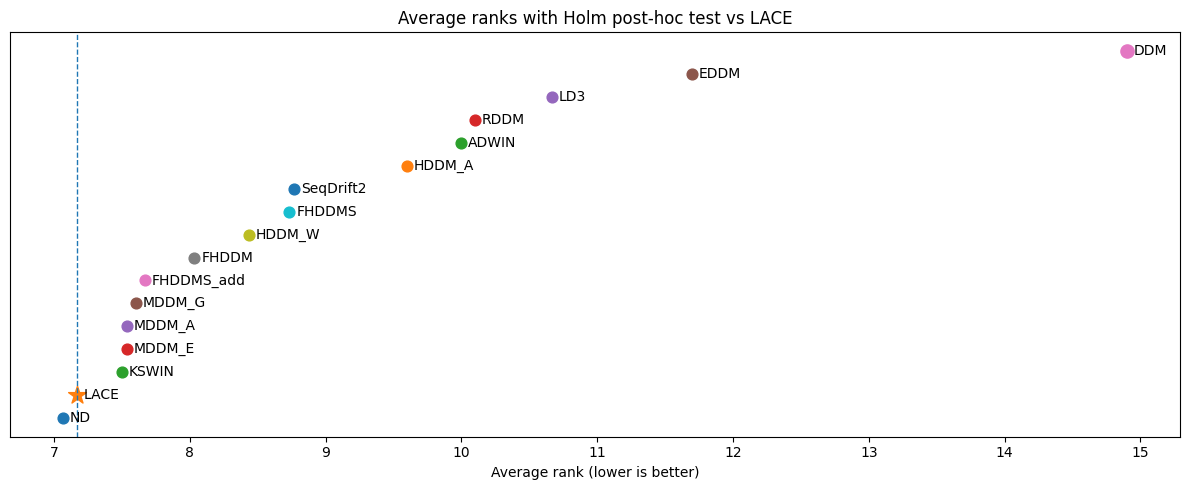

In [67]:
control = "LACE"
alpha = 0.05
df = df_no_synth_accuracy
friedman_stat, friedman_p = friedmanchisquare(
    *[df[col].values for col in df.columns]
)

print("Friedman statistic:", friedman_stat)
print("Friedman p-value:", friedman_p)

ranks = df.rank(axis=1, ascending=False, method="average")
avg_ranks = ranks.mean(axis=0).sort_values()

print(avg_ranks)

k = df.shape[1]
N = df.shape[0]

se = np.sqrt(k * (k + 1) / (6 * N))
control_rank = avg_ranks[control]

rows = []

for method in df.columns:
    if method == control:
        continue

    method_rank = avg_ranks[method]
    rank_diff = abs(control_rank - method_rank)
    z = rank_diff / se
    raw_p = 2 * (1 - norm.cdf(abs(z)))

    rows.append({
        "comparison": f"{control} vs {method}",
        "method": method,
        "OUR_avg_rank": control_rank,
        "method_avg_rank": method_rank,
        "rank_difference": rank_diff,
        "raw_p": raw_p,
    })

holm_results = pd.DataFrame(rows)

reject, holm_p, _, _ = multipletests(
    holm_results["raw_p"],
    alpha=alpha,
    method="holm"
)

holm_results["holm_p"] = holm_p
holm_results["significant"] = reject

holm_results = holm_results.sort_values("holm_p")

holm_results.to_csv("/Users/mehmetkadrigofralilar/Desktop/holm_results.csv", index=False)

print(holm_results)

plot_df = holm_results[["method", "method_avg_rank", "significant"]].rename(
    columns={"method_avg_rank": "avg_rank"}
)

plot_df["better_than_OUR"] = plot_df["avg_rank"] < control_rank
plot_df["worse_than_OUR"] = plot_df["avg_rank"] > control_rank

control_row = pd.DataFrame({
    "method": [control],
    "avg_rank": [control_rank],
    "significant": [False],
    "better_than_OUR": [False],
    "worse_than_OUR": [False],
})

plot_df = pd.concat([plot_df, control_row], ignore_index=True)

# Worst at top, best at bottom
plot_df = plot_df.sort_values("avg_rank", ascending=True).reset_index(drop=True)

plt.figure(figsize=(12, 5))

for i, row in plot_df.iterrows():
    if row["method"] == control:
        marker = "*"
        size = 180
    elif row["significant"] and row["better_than_OUR"]:
        marker = "X"
        size = 90
    elif row["significant"] and row["worse_than_OUR"]:
        marker = "o"
        size = 90
    else:
        marker = "o"
        size = 60

    plt.scatter(row["avg_rank"], i, s=size, marker=marker)
    plt.text(row["avg_rank"] + 0.05, i, row["method"], va="center")

plt.axvline(control_rank, linestyle="--", linewidth=1)

plt.xlabel("Average rank (lower is better)")
plt.title("Average ranks with Holm post-hoc test vs LACE")
plt.yticks([])
plt.tight_layout()
plt.savefig("/Users/mehmetkadrigofralilar/Desktop/average_ranks_plot.png")
plt.show()

Friedman statistic: 77.65318371607505
Friedman p-value: 2.1986878248146004e-09
LD3.pkl                            6.111111
RDDM.pkl                           6.750000
LACE.pkl                           7.583333
ADWIN.pkl                          8.444444
MDDM_E.pkl                         8.944444
ND.pkl                             8.944444
MDDM_A.pkl                         8.972222
LACE-KMeans_Variant.pkl            9.000000
MDDM_G.pkl                         9.138889
LACE-Agglomerative_Variant.pkl     9.444444
FHDDM.pkl                         10.083333
FHDDMS_add.pkl                    10.138889
FHDDMS.pkl                        10.694444
KSWIN.pkl                         11.027778
SeqDrift2.pkl                     11.138889
HDDM_W.pkl                        11.555556
HDDM_A.pkl                        12.138889
EDDM.pkl                          13.527778
DDM.pkl                           16.361111
dtype: float64
                                    comparison  \
9                   

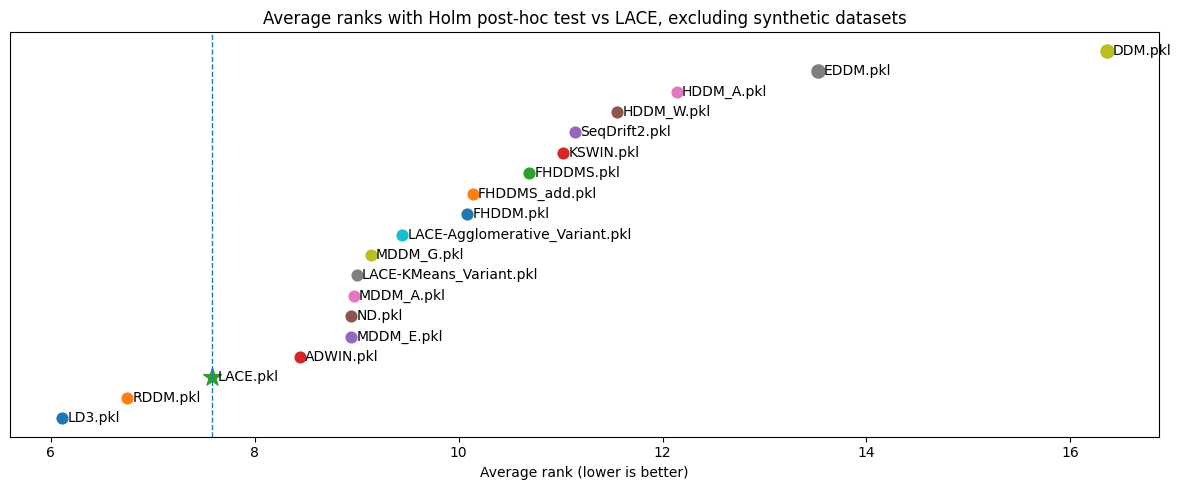

In [82]:
control = "LACE.pkl"
alpha = 0.05

friedman_stat_no_synth, friedman_p_no_synth = friedmanchisquare(
    *[df_no_synth[col].values for col in df_no_synth.columns]
)

print("Friedman statistic:", friedman_stat_no_synth)
print("Friedman p-value:", friedman_p_no_synth)

ranks_no_synth = df_no_synth.rank(axis=1, ascending=False, method="average")
avg_ranks_no_synth = ranks_no_synth.mean(axis=0).sort_values()

print(avg_ranks_no_synth)

k_no_synth = df_no_synth.shape[1]
N_no_synth = df_no_synth.shape[0]

se_no_synth = np.sqrt(k_no_synth * (k_no_synth + 1) / (6 * N_no_synth))
control_rank_no_synth = avg_ranks_no_synth[control]

rows_no_synth = []

for method in df_no_synth.columns:
    if method == control:
        continue

    method_rank = avg_ranks_no_synth[method]
    rank_diff = abs(control_rank_no_synth - method_rank)
    z = rank_diff / se_no_synth
    raw_p = 2 * (1 - norm.cdf(abs(z)))

    rows_no_synth.append({
        "comparison": f"{control} vs {method}",
        "method": method,
        "OUR_avg_rank": control_rank_no_synth,
        "method_avg_rank": method_rank,
        "rank_difference": rank_diff,
        "raw_p": raw_p,
    })

holm_results_no_synth = pd.DataFrame(rows_no_synth)

reject_no_synth, holm_p_no_synth, _, _ = multipletests(
    holm_results_no_synth["raw_p"],
    alpha=alpha,
    method="holm"
)

holm_results_no_synth["holm_p"] = holm_p_no_synth
holm_results_no_synth["significant"] = reject_no_synth

holm_results_no_synth = holm_results_no_synth.sort_values("holm_p")

holm_results_no_synth.to_csv("/Users/mehmetkadrigofralilar/Desktop/holm_results_no_synth.csv", index=False)

print(holm_results_no_synth)

plot_df_no_synth = holm_results_no_synth[
    ["method", "method_avg_rank", "significant"]
].rename(columns={"method_avg_rank": "avg_rank"})

plot_df_no_synth["better_than_OUR"] = (
    plot_df_no_synth["avg_rank"] < control_rank_no_synth
)
plot_df_no_synth["worse_than_OUR"] = (
    plot_df_no_synth["avg_rank"] > control_rank_no_synth
)

control_row_no_synth = pd.DataFrame({
    "method": [control],
    "avg_rank": [control_rank_no_synth],
    "significant": [False],
    "better_than_OUR": [False],
    "worse_than_OUR": [False],
})

plot_df_no_synth = pd.concat(
    [plot_df_no_synth, control_row_no_synth],
    ignore_index=True
)

plot_df_no_synth = plot_df_no_synth.sort_values(
    "avg_rank",
    ascending=True
).reset_index(drop=True)

plt.figure(figsize=(12, 5))

for i, row in plot_df_no_synth.iterrows():
    if row["method"] == control:
        marker = "*"
        size = 180
    elif row["significant"] and row["better_than_OUR"]:
        marker = "X"
        size = 90
    elif row["significant"] and row["worse_than_OUR"]:
        marker = "o"
        size = 90
    else:
        marker = "o"
        size = 60

    plt.scatter(row["avg_rank"], i, s=size, marker=marker)
    plt.text(row["avg_rank"] + 0.05, i, row["method"], va="center")

plt.axvline(control_rank_no_synth, linestyle="--", linewidth=1)

plt.xlabel("Average rank (lower is better)")
plt.title("Average ranks with Holm post-hoc test vs LACE, excluding synthetic datasets")
plt.yticks([])
plt.tight_layout()
plt.savefig("/Users/mehmetkadrigofralilar/Desktop/average_ranks_no_synth_plot.png")
plt.show()

# Latex Table Converter

In [11]:
import os

os.chdir("/Users/mehmetkadrigofralilar/Desktop/lace_og/outputs/tables_figures/effectiveness")

In [12]:
files = [file for file in os.listdir() if file.endswith('.csv')]

In [13]:
import pandas as pd
import numpy as np

# =========================
# USER SETTINGS
# =========================

csv_path = files[0]
output_tex_path = "table_output.tex"

calculate_rank = True
rank_criteria = "big"

highlight_criteria = "big"
highlight_second_best = True

caption = "Predictive effectiveness comparison of the evaluated drift detectors across real datasets. Best values are shown in bold and underlined, second-best values are underlined."
label = "tab:method_comparison"

highlight_rank = False

float_format = 4

table_font_size = r"\tiny"
tabcolsep = "1.5pt"
arraystretch = "0.50"
resize_to_width = r"\linewidth"
use_resizebox = True


# =========================
# HELPER FUNCTIONS
# =========================

def latex_escape(text):
    text = str(text)

    replacements = {
        "\\": r"\textbackslash{}",
        "_": r"\_",
        "%": r"\%",
        "&": r"\&",
        "#": r"\#",
        "$": r"\$",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }

    for old, new in replacements.items():
        text = text.replace(old, new)

    return text


def format_value(value, float_format):
    if pd.isna(value):
        return "N/A"
    elif isinstance(value, (int, np.integer)):
        return str(value)
    elif isinstance(value, (float, np.floating)):
        return f"{value:.{float_format}f}"
    else:
        return str(value)


def get_best_mask(row_values, criterion):
    """
    Return boolean mask for best values.
    Ties are all highlighted.
    """
    numeric_values = pd.to_numeric(row_values, errors="coerce")

    if numeric_values.isna().all():
        return pd.Series(False, index=row_values.index)

    if criterion == "big":
        best_value = numeric_values.max()
    elif criterion == "small":
        best_value = numeric_values.min()
    else:
        raise ValueError("highlight_criteria must be either 'big' or 'small'.")

    return numeric_values == best_value


def get_second_best_mask(row_values, criterion):
    """
    Return boolean mask for second-best values.
    Ties are all highlighted.

    If all non-NaN values are tied, no second-best value exists.
    """
    numeric_values = pd.to_numeric(row_values, errors="coerce")

    if numeric_values.isna().all():
        return pd.Series(False, index=row_values.index)

    if criterion == "big":
        best_value = numeric_values.max()
        candidates = numeric_values[numeric_values < best_value]

        if candidates.empty:
            return pd.Series(False, index=row_values.index)

        second_best_value = candidates.max()

    elif criterion == "small":
        best_value = numeric_values.min()
        candidates = numeric_values[numeric_values > best_value]

        if candidates.empty:
            return pd.Series(False, index=row_values.index)

        second_best_value = candidates.min()

    else:
        raise ValueError("highlight_criteria must be either 'big' or 'small'.")

    return numeric_values == second_best_value


def order_methods(methods):
    """
    Order methods as:
    LACE, LD3, then the rest in their existing order, then ND.
    """
    preferred_start = ["LACE", "LD3"]
    preferred_end = ["ND"]

    methods = list(methods)

    start = [m for m in preferred_start if m in methods]
    end = [m for m in preferred_end if m in methods]

    middle = [
        m for m in methods
        if m not in preferred_start and m not in preferred_end
    ]

    return start + middle + end


# =========================
# LATEX TABLE GENERATOR
# =========================

def dataframe_to_latex_table(
    df,
    calculate_rank=True,
    highlight_criteria="big",
    rank_criteria="big",
    caption=None,
    label=None,
    float_format=4,
):

    df = df.copy()

    dataset_col = df.columns[0]

    # Shorten synthetic dataset names.
    df[dataset_col] = df[dataset_col].astype(str).str.replace(
        "Synthetic_",
        "Synth_",
        case=False,
        regex=False,
    )

    # Method columns after filtering.
    method_cols = list(df.columns[1:])
    method_cols = order_methods(method_cols)

    # Keep only dataset + ordered method columns.
    df = df[[dataset_col] + method_cols]

    # Convert scores to numeric.
    for col in method_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    # =========================
    # Average rank calculation
    # =========================

    avg_ranks = None

    if calculate_rank:
        ascending = rank_criteria == "small"

        ranks = df[method_cols].rank(
            axis=1,
            method="average",
            ascending=ascending,
        )

        avg_ranks = ranks.mean(axis=0)

    # =========================
    # Build LaTeX
    # =========================

    column_format = "l" + "c" * len(method_cols)

    lines = []

    lines.append(r"\begin{table*}[t]")
    lines.append(r"\centering")
    lines.append(table_font_size)
    lines.append(r"\setlength{\tabcolsep}{" + tabcolsep + r"}")
    lines.append(r"\renewcommand{\arraystretch}{" + arraystretch + r"}")

    if use_resizebox:
        lines.append(r"\resizebox{" + resize_to_width + r"}{!}{%")

    lines.append(r"\begin{tabular}{" + column_format + r"}")
    lines.append(r"\toprule")

    header = [latex_escape(dataset_col)] + [latex_escape(col) for col in method_cols]
    lines.append(" & ".join(header) + r" \\")
    lines.append(r"\midrule")

    # =========================
    # Body rows
    # =========================

    for _, row in df.iterrows():
        row_cells = [latex_escape(row[dataset_col])]

        row_values = row[method_cols]

        best_mask = get_best_mask(row_values, highlight_criteria)

        if highlight_second_best:
            second_best_mask = get_second_best_mask(row_values, highlight_criteria)
        else:
            second_best_mask = pd.Series(False, index=row_values.index)

        for col in method_cols:
            cell = format_value(row[col], float_format)

            if best_mask[col]:
                cell = r"\textbf{\underline{" + cell + "}}"
            elif second_best_mask[col]:
                cell = r"\underline{" + cell + "}"

            row_cells.append(cell)

        lines.append(" & ".join(row_cells) + r" \\")

    # =========================
    # Average rank row
    # =========================

    if calculate_rank:
        lines.append(r"\midrule")

        avg_rank_cells = [r"\textbf{Average Rank}"]

        smallest_rank = avg_ranks.min()

        for col in method_cols:
            cell = format_value(avg_ranks[col], float_format)

            if avg_ranks[col] == smallest_rank and highlight_rank:
                cell = r"\textbf{\underline{" + cell + "}}"

            avg_rank_cells.append(cell)

        lines.append(" & ".join(avg_rank_cells) + r" \\")

    lines.append(r"\bottomrule")
    lines.append(r"\end{tabular}")

    if use_resizebox:
        lines.append(r"}")

    if caption is not None:
        lines.append(r"\caption{" + latex_escape(caption) + r"}")

    if label is not None:
        lines.append(r"\label{" + label + r"}")

    lines.append(r"\end{table*}")

    return "\n".join(lines)


# =========================
# MAIN
# =========================

df = pd.read_csv(csv_path)

latex_table = dataframe_to_latex_table(
    df=df,
    calculate_rank=calculate_rank,
    highlight_criteria=highlight_criteria,
    rank_criteria=rank_criteria,
    caption=caption,
    label=label,
    float_format=float_format,
)

print(latex_table)

with open(output_tex_path, "w", encoding="utf-8") as f:
    f.write(latex_table)

print(f"\nLaTeX table saved to: {output_tex_path}")

\begin{table*}[t]
\centering
\tiny
\setlength{\tabcolsep}{1.5pt}
\renewcommand{\arraystretch}{0.50}
\resizebox{\linewidth}{!}{%
\begin{tabular}{lccccccccccccccccc}
\toprule
Dataset & LACE & LD3 & SeqDrift2 & MDDM\_E & ADWIN & DDM & KSWIN & MDDM\_A & EDDM & HDDM\_A & HDDM\_W & FHDDMS & FHDDM & MDDM\_G & RDDM & FHDDMS\_add & ND \\
\midrule
Birds & \textbf{\underline{0.2149}} & 0.1530 & 0.2135 & 0.2135 & 0.2135 & 0.1834 & 0.2135 & 0.2135 & 0.2135 & 0.2135 & 0.2135 & 0.2135 & 0.2135 & 0.2135 & \underline{0.2144} & 0.2135 & 0.2135 \\
Enron & \underline{0.2512} & \textbf{\underline{0.2520}} & 0.2236 & 0.2090 & 0.2169 & 0.2037 & 0.2081 & 0.2091 & 0.2156 & 0.2177 & 0.2177 & 0.2082 & 0.2082 & 0.2090 & 0.2063 & 0.2103 & 0.2177 \\
Eukaryote & 0.0822 & \underline{0.1084} & 0.0726 & 0.0726 & 0.0726 & 0.0726 & 0.0726 & 0.0726 & 0.0726 & 0.0726 & 0.0726 & 0.0726 & 0.0726 & 0.0726 & \textbf{\underline{0.2909}} & 0.0726 & 0.0726 \\
Gnegative & 0.3976 & \textbf{\underline{0.4263}} & 0.2226 & \underline{

In [29]:
import pandas as pd
import numpy as np

# =========================
# USER SETTINGS
# =========================

metric_csvs = {
    "Acc.": "accuracies.csv",
    "F1-mi.": "f1_micro_scores.csv",
    "F1-ma.": "f1_macro_scores.csv",
}

output_tex_path = "table_output_all_metrics.tex"

caption = (
    "Predictive effectiveness comparison of the evaluated drift detectors "
    "across real datasets and metrics. Best values are shown in bold and "
    "underlined, second-best values are underlined."
)
label = "tab:method_comparison_all_metrics"

highlight_second_best = True

# Higher is better for accuracy/F1, lower is better for hamming loss.
metric_criteria = {
    "Acc.": "big",
    "F1-mi.": "big",
    "F1-ma.": "big",
}

float_format = 4

table_font_size = r"\tiny"
tabcolsep = "1.5pt"
arraystretch = "0.55"
resize_to_width = r"\textwidth"
use_resizebox = True

# Optional filtering
remove_synthetic = True

# Optional method ordering
preferred_start = ["LACE", "LD3"]
preferred_end = ["ND"]


# =========================
# HELPER FUNCTIONS
# =========================

def latex_escape(text):
    text = str(text)

    replacements = {
        "\\": r"\textbackslash{}",
        "_": r"\_",
        "%": r"\%",
        "&": r"\&",
        "#": r"\#",
        "$": r"\$",
        "{": r"\{",
        "}": r"\}",
        "~": r"\textasciitilde{}",
        "^": r"\textasciicircum{}",
    }

    for old, new in replacements.items():
        text = text.replace(old, new)

    return text


def format_value(value, float_format):
    if pd.isna(value):
        return "--"
    elif isinstance(value, (int, np.integer)):
        return str(value)
    elif isinstance(value, (float, np.floating)):
        return f"{value:.{float_format}f}"
    else:
        return str(value)


def order_methods(methods):
    methods = list(methods)

    start = [m for m in preferred_start if m in methods]
    end = [m for m in preferred_end if m in methods]

    middle = [
        m for m in methods
        if m not in preferred_start and m not in preferred_end
    ]

    return start + middle + end


def get_best_and_second_masks(values, criterion):

    numeric_values = pd.to_numeric(values, errors="coerce")

    best_mask = pd.Series(False, index=values.index)
    second_mask = pd.Series(False, index=values.index)

    if numeric_values.isna().all():
        return best_mask, second_mask

    if criterion == "big":
        best_value = numeric_values.max()
        best_mask = numeric_values == best_value

        candidates = numeric_values[numeric_values < best_value]
        if not candidates.empty:
            second_value = candidates.max()
            second_mask = numeric_values == second_value

    elif criterion == "small":
        best_value = numeric_values.min()
        best_mask = numeric_values == best_value

        candidates = numeric_values[numeric_values > best_value]
        if not candidates.empty:
            second_value = candidates.min()
            second_mask = numeric_values == second_value

    else:
        raise ValueError("criterion must be either 'big' or 'small'.")

    return best_mask, second_mask


# =========================
# DATA LOADING
# =========================

def load_metric_tables(metric_csvs, remove_synthetic=True):
    """
    Returns:
        metric_tables[metric_name] = dataframe indexed by Dataset,
        columns = methods
    """

    metric_tables = {}

    for metric_name, csv_path in metric_csvs.items():
        df = pd.read_csv(csv_path)

        dataset_col = df.columns[0]
        df[dataset_col] = df[dataset_col].astype(str)

        df = df.set_index(dataset_col)

        for col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

        metric_tables[metric_name] = df

    return metric_tables


def get_common_datasets_and_methods(metric_tables):
    """
    Keeps only datasets and methods that exist in every metric table.
    """

    common_datasets = None
    common_methods = None

    for _, df in metric_tables.items():
        datasets = set(df.index)
        methods = set(df.columns)

        if common_datasets is None:
            common_datasets = datasets
        else:
            common_datasets &= datasets

        if common_methods is None:
            common_methods = methods
        else:
            common_methods &= methods

    # Preserve dataset order from the first metric file.
    first_metric = next(iter(metric_tables))
    dataset_order = [
        d for d in metric_tables[first_metric].index
        if d in common_datasets
    ]

    method_order = order_methods([
        m for m in metric_tables[first_metric].columns
        if m in common_methods
    ])

    return dataset_order, method_order


# =========================
# LATEX TABLE GENERATOR
# =========================

def metrics_to_latex_table(
    metric_csvs,
    metric_criteria,
    caption=None,
    label=None,
    float_format=4,
    remove_synthetic=True,
):
    metric_tables = load_metric_tables(
        metric_csvs=metric_csvs,
        remove_synthetic=remove_synthetic,
    )

    metric_names = list(metric_csvs.keys())
    datasets, methods = get_common_datasets_and_methods(metric_tables)

    n_metrics = len(metric_names)

    # Column format:
    # one method column + one centered column per dataset/metric pair
    column_format = "l|"

    for dataset_idx, _ in enumerate(datasets):
        column_format += "c" * n_metrics

        if dataset_idx < len(datasets) - 1:
            column_format += "|"

    lines = []

    lines.append(r"\begin{table*}[t]")
    lines.append(r"\centering")
    lines.append(table_font_size)
    lines.append(r"\setlength{\tabcolsep}{" + tabcolsep + r"}")
    lines.append(r"\renewcommand{\arraystretch}{" + arraystretch + r"}")

    if use_resizebox:
        lines.append(r"\resizebox{" + resize_to_width + r"}{!}{%")

    lines.append(r"\begin{tabular}{" + column_format + r"}")
    lines.append(r"\toprule")

    # =========================
    # Header row 1: Dataset groups
    # =========================

    header_1 = [""]

    cmidrules = []
    current_col = 2  # LaTeX columns are 1-indexed; Method is col 1.

    for dataset in datasets:
        start_col = current_col
        end_col = current_col + n_metrics - 1

        if dataset == datasets[-1]:
            multicol_align = "c"
        else:
            multicol_align = "c|"

        header_1.append(
            r"\multicolumn{" + str(n_metrics) + r"}{" + multicol_align + r"}{" +
            latex_escape(dataset) +
            r"}"
        )

        cmidrules.append(
            r"\cmidrule(lr){" + str(start_col) + "-" + str(end_col) + r"}"
        )

        current_col += n_metrics

    lines.append(" & ".join(header_1) + r" \\")
    lines.append(" ".join(cmidrules))

    # =========================
    # Header row 2: Metrics
    # =========================

    header_2 = ["Method"]

    for _ in datasets:
        for metric_name in metric_names:
            header_2.append(latex_escape(metric_name))

    lines.append(" & ".join(header_2) + r" \\")
    lines.append(r"\midrule")

    # =========================
    # Precompute highlights
    # =========================

    highlight_info = {}

    for dataset in datasets:
        for metric_name in metric_names:
            values = metric_tables[metric_name].loc[dataset, methods]
            criterion = metric_criteria[metric_name]

            best_mask, second_mask = get_best_and_second_masks(
                values=values,
                criterion=criterion,
            )

            highlight_info[(dataset, metric_name)] = {
                "best": best_mask,
                "second": second_mask,
            }


    # =========================
    # Body: Methods as rows
    # =========================

    for method in methods:
        row_cells = [latex_escape(method)]

        for dataset in datasets:
            for metric_name in metric_names:
                value = metric_tables[metric_name].loc[dataset, method]
                cell = format_value(value, float_format)

                best_mask = highlight_info[(dataset, metric_name)]["best"]
                second_mask = highlight_info[(dataset, metric_name)]["second"]

                if best_mask[method]:
                    cell = r"\textbf{\underline{" + cell + "}}"
                elif highlight_second_best and second_mask[method]:
                    cell = r"\underline{" + cell + "}"

                row_cells.append(cell)

        lines.append(" & ".join(row_cells) + r" \\")

    lines.append(r"\bottomrule")
    lines.append(r"\end{tabular}")

    if use_resizebox:
        lines.append(r"}")

    if caption is not None:
        lines.append(r"\caption{" + latex_escape(caption) + r"}")

    if label is not None:
        lines.append(r"\label{" + label + r"}")

    lines.append(r"\end{table*}")

    return "\n".join(lines)


# =========================
# MAIN
# =========================

latex_table = metrics_to_latex_table(
    metric_csvs=metric_csvs,
    metric_criteria=metric_criteria,
    caption=caption,
    label=label,
    float_format=float_format,
    remove_synthetic=remove_synthetic,
)

print(latex_table)

with open(output_tex_path, "w", encoding="utf-8") as f:
    f.write(latex_table)

print(f"\nLaTeX table saved to: {output_tex_path}")

\begin{table*}[t]
\centering
\tiny
\setlength{\tabcolsep}{1.5pt}
\renewcommand{\arraystretch}{0.55}
\resizebox{\textwidth}{!}{%
\begin{tabular}{l|ccc|ccc|ccc|ccc|ccc|ccc|ccc|ccc|ccc|ccc|ccc|ccc}
\toprule
 & \multicolumn{3}{c|}{Birds} & \multicolumn{3}{c|}{Enron} & \multicolumn{3}{c|}{Eukaryote} & \multicolumn{3}{c|}{Gnegative} & \multicolumn{3}{c|}{Human} & \multicolumn{3}{c|}{Imdb} & \multicolumn{3}{c|}{Mediamill} & \multicolumn{3}{c|}{OHSUMED-F} & \multicolumn{3}{c|}{Plant} & \multicolumn{3}{c|}{Slashdot} & \multicolumn{3}{c|}{tmc2007-500} & \multicolumn{3}{c}{yeast} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10} \cmidrule(lr){11-13} \cmidrule(lr){14-16} \cmidrule(lr){17-19} \cmidrule(lr){20-22} \cmidrule(lr){23-25} \cmidrule(lr){26-28} \cmidrule(lr){29-31} \cmidrule(lr){32-34} \cmidrule(lr){35-37}
Method & Acc. & F1-mi. & F1-ma. & Acc. & F1-mi. & F1-ma. & Acc. & F1-mi. & F1-ma. & Acc. & F1-mi. & F1-ma. & Acc. & F1-mi. & F1-ma. & Acc. & F1-mi. & F1-ma. & Acc. & F1-mi. &